In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os
warnings.filterwarnings('ignore')

# ========== CREATE BOXPLOTS FOR EACH PARTICIPANTID ==========
print("=" * 80)
print("CREATING UTCI + ETTERBEEK HOURLY WEATHER BOXPLOTS BY PHASE")
print("=" * 80)

DATA_FILE = r"C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Complete Participantwise data\external data input\ExperimentData_11Feb.csv"
WEATHER_FILE = r"C:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\etterbeek_station_openmeteo_experiment_dates_hourly.csv"
OUTPUT_DIR = r"C:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\New folder"
KEY_TO_WEATHER_OFFSET = pd.Timedelta(hours=2)  # key/experiment timestamps are 2 h behind Brussels weather time
PHASE_ORDER = ["BikeG", "WalkG", "WalkU", "BikeU"]


def read_csv_any_encoding(path):
    for encoding in ['utf-8', 'latin-1', 'iso-8859-1', 'cp1252', 'utf-8-sig']:
        try:
            df = pd.read_csv(path, encoding=encoding, low_memory=False)
            print(f"Loaded {os.path.basename(path)} with {encoding}: {len(df)} rows")
            return df
        except UnicodeDecodeError:
            continue
    raise RuntimeError(f"Could not read file with standard encodings: {path}")


def style_boxplot(bp, facecolor):
    for patch in bp['boxes']:
        patch.set_facecolor(facecolor)
        patch.set_alpha(0.72)
    for whisker in bp['whiskers']:
        whisker.set(linewidth=1.3, color='#333333')
    for cap in bp['caps']:
        cap.set(linewidth=1.3, color='#333333')
    for median in bp['medians']:
        median.set(linewidth=2.0, color='red')
    for mean in bp['means']:
        mean.set(marker='D', markerfacecolor='green', markeredgecolor='green', markersize=6)


def metric_values(participant_df, phase, col, unique_hourly=False):
    sub = participant_df[participant_df['PhaseID'] == phase].copy()
    if unique_hourly and 'weather_hour' in sub.columns:
        sub = sub.drop_duplicates('weather_hour')
    return pd.to_numeric(sub[col], errors='coerce').dropna().to_numpy(dtype=float)


df = read_csv_any_encoding(DATA_FILE)
weather = pd.read_csv(WEATHER_FILE, low_memory=False)
weather['timestamp'] = pd.to_datetime(weather['timestamp'], errors='coerce')
weather = weather.dropna(subset=['timestamp']).drop_duplicates('timestamp')
weather_cols = ['timestamp', 'relative_humidity_2m_pct', 'temperature_2m_C', 'wind_speed_10m_kmh']
weather = weather[weather_cols]

df['ParticipantID'] = pd.to_numeric(df['ParticipantID'], errors='coerce')
df['PhaseID'] = df['PhaseID'].astype(str)
df = df[df['PhaseID'].isin(PHASE_ORDER)].copy()
df['key_datetime'] = pd.to_datetime(
    df['Date'].astype(str).str.strip() + ' ' + df['Time'].astype(str).str.strip(),
    format='%d-%m-%y %H:%M', errors='coerce'
)
df['weather_datetime'] = df['key_datetime'] + KEY_TO_WEATHER_OFFSET
df['weather_hour'] = df['weather_datetime'].dt.floor('h')
df = df.merge(weather, left_on='weather_hour', right_on='timestamp', how='left')

utci_cols = [col for col in df.columns if 'utci' in col.lower()]
if not utci_cols:
    raise RuntimeError('No UTCI column found')
utci_col = utci_cols[0]
print(f"Using UTCI column: {utci_col}")
print(f"Weather alignment: Date+Time + {KEY_TO_WEATHER_OFFSET} -> hourly Etterbeek row")

os.makedirs(OUTPUT_DIR, exist_ok=True)
participant_ids = sorted([pid for pid in df['ParticipantID'].dropna().unique()])
print(f"Found {len(participant_ids)} participants: {participant_ids}")

metrics = [
    ('UTCI', utci_col, 'UTCI (deg C)', '#808080', False),
    ('RH', 'relative_humidity_2m_pct', 'Etterbeek RH (%)', '#7BA6D8', True),
    ('Air temperature', 'temperature_2m_C', 'Etterbeek air temp (deg C)', '#F4A261', True),
    ('Wind speed', 'wind_speed_10m_kmh', 'Etterbeek wind speed 10 m (km/h)', '#66A182', True),
]

for participant_id in participant_ids:
    participant_df = df[df['ParticipantID'] == participant_id].copy()
    if participant_df.empty:
        continue
    available_phases = [phase for phase in PHASE_ORDER if phase in participant_df['PhaseID'].unique()]
    if not available_phases:
        continue
    date_str = participant_df['Date'].dropna().astype(str).iloc[0] if 'Date' in participant_df.columns else 'NA'

    fig, axes = plt.subplots(len(metrics), 1, figsize=(12, 12), sharex=True)
    fig.suptitle(
        f'Participant {int(participant_id)} | Date: {date_str} | weather matched as key time + 2 h',
        fontsize=14, fontweight='bold', y=0.995
    )

    for ax, (label, col, ylabel, color, unique_hourly) in zip(axes, metrics):
        values = [metric_values(participant_df, phase, col, unique_hourly=unique_hourly) for phase in available_phases]
        plot_values = [v if len(v) else np.array([np.nan]) for v in values]
        bp = ax.boxplot(plot_values, labels=available_phases, patch_artist=True, widths=0.6, showmeans=True)
        style_boxplot(bp, color)
        ax.set_ylabel(ylabel, fontsize=11, fontweight='bold')
        ax.set_title(label, fontsize=11, fontweight='bold', loc='left')
        ax.grid(True, alpha=0.3, axis='y')
        if unique_hourly:
            counts = ', '.join(f"{phase}: {len(values[i])} h" for i, phase in enumerate(available_phases))
            ax.text(0.99, 0.92, counts, ha='right', va='top', fontsize=8, transform=ax.transAxes, color='#555555')

    axes[-1].set_xlabel('Phase', fontsize=12, fontweight='bold')
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], color='red', lw=2, label='Median'),
        Line2D([0], [0], marker='D', color='w', markerfacecolor='green', markeredgecolor='green', markersize=7, label='Mean'),
    ]
    axes[0].legend(handles=legend_elements, loc='best', fontsize=9)
    plt.tight_layout(rect=[0, 0, 1, 0.97])

    svg_filename = f"Participant_{int(participant_id)}_UTCI_Weather_Boxplot.svg"
    svg_path = os.path.join(OUTPUT_DIR, svg_filename)
    plt.savefig(svg_path, format='svg', dpi=300, bbox_inches='tight')
    plt.close()
    print(f"Saved: {svg_filename}")

print("=" * 80)
print(f"All updated boxplots saved to: {OUTPUT_DIR}")
print("=" * 80)



CREATING BOXPLOTS: UTCI BY PHASEID FOR EACH PARTICIPANT
Trying encoding: utf-8... ✓ Success!

✓ Data loaded with utf-8 encoding: 2517 rows, 264 columns

✓ Using column: ucm__utci

✓ Output directory: C:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\New folder

Found 18 participants: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]

Phase order: ['BikeG', 'WalkG', 'WalkU', 'BikeU']

Processing Participant 1... ✅ Saved: Participant_1_UTCI_Boxplot.svg
  Statistics for Participant 1:
    BikeG: N=15, Mean=23.26±2.40, Median=22.25
    WalkG: N=35, Mean=23.75±2.25, Median=23.09
    WalkU: N=27, Mean=27.27±4.82, Median=29.20
    BikeU: N=32, Mean=28.47±2.76, Median=29.28
Processing Participant 2... ✅ Saved: Participant_2_UTCI_Boxplot.svg
  Statistics for Participant 2:
    BikeG: N=20, Mean=24.85±1.6

In [6]:
# Load Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
from IPython.display import SVG, display
warnings.filterwarnings('ignore')

# Set style for better visualizations
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

# Define Consistent Color System
# PhaseID Colors
phase_colors = {
    'BikeG': '#006400',      # Dark Green
    'WalkG': '#90EE90',      # Light Green
    'BikeU': '#000000',      # Black
    'WalkU': '#808080',      # Grey
    'Tram': '#FFA500',       # Orange
    'Indoor': '#8B0000',     # Dark Red
    'reststop': '#4B0082'    # Indigo
}

# 18 Distinct Dark Colors for ParticipantID (No yellow or light colors)
participant_colors = [
    '#1f77b4', '#d62728', '#2ca02c', '#9467bd', '#8c564b', 
    '#e377c2', '#7f7f7f', '#17becf', '#000080', '#800000',
    '#006400', '#4b0082', '#556b2f', '#8b4513', '#2f4f4f',
    '#8b008b', '#4682b4', '#191970'  # Replaced black/yellow with distinct darks
]

# Load and Show Experiment Map
map_path = r"C:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 1 - Literature Review\Diagram\Experiment Map.svg"
display(SVG(filename=map_path))

# Load the data
file_path = r"C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Experiment material\ExperimentData_09March.csv"
df = pd.read_csv(file_path)

# Filter: Exclude ParticipantID 1 as requested
df = df[df['ParticipantID'] != 1]

# Convert categorical comfort columns to numeric (FIXED: 1-5 scale to cover the full spectrum)
comfort_mapping = {
    'Comfortable': 5,
    'Slightly non comfortable': 4,
    'Non comfortable': 3,
    'Very uncomfortable': 2,
    'Extremely uncomfortable': 1
}

comfort_cols = ['Comfort-Thermal', 'Comfort-Acoustic', 'Comfort-Visual', 'Comfort-AQ', 'Comfort-Smell']
for col in comfort_cols:
    df[f"{col}_Numeric"] = df[col].map(comfort_mapping)

buffer_df = pd.read_csv(r"C:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\QGIS\Buffer 50m.csv")

In [7]:
# Define Haversine distance function FIRST
def haversine_dist(lat1, lon1, lat2_ser, lon2_ser):
    R = 6371000  # Earth radius in meters
    p = np.pi / 180
    lat2 = lat2_ser.values if hasattr(lat2_ser, 'values') else lat2_ser
    lon2 = lon2_ser.values if hasattr(lon2_ser, 'values') else lon2_ser
    a = 0.5 - np.cos((lat2 - lat1) * p) / 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * (1 - np.cos((lon2 - lon1) * p)) / 2
    return 2 * R * np.arcsin(np.sqrt(a))

# 1. Define buffer_df from user-provided data (FIXED: removed duplicate lat at 50.829867)
ids = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56]
lats = [50.802802, 50.803956, 50.805117, 50.806403, 50.807742, 50.809018, 50.810252, 50.811565, 50.812791, 50.814064, 50.815352, 50.816410, 50.817362, 50.818394, 50.819359, 50.819984, 50.820587, 50.821265, 50.821997, 50.822842, 50.823693, 50.824544, 50.825392, 50.826220, 50.827031, 50.827860, 50.828819, 50.829867, 50.831041, 50.832290, 50.833560, 50.834841, 50.836123, 50.817449, 50.801800, 50.802788, 50.803939, 50.805248, 50.806460, 50.807255, 50.808125, 50.808977, 50.809594, 50.810668, 50.811882, 50.813109, 50.814130, 50.814218, 50.813780, 50.812789, 50.811454, 50.810168, 50.809020, 50.807988, 50.807108, 50.806686]
lons = [4.390409, 4.389307, 4.388225, 4.387685, 4.387435, 4.386830, 4.385975, 4.385718, 4.384831, 4.384170, 4.383617, 4.382318, 4.380811, 4.379695, 4.381146, 4.383016, 4.384914, 4.386754, 4.388541, 4.390201, 4.391854, 4.393505, 4.395161, 4.396843, 4.398543, 4.400223, 4.401719, 4.403047, 4.404076, 4.404878, 4.405595, 4.406263, 4.406923, 4.378862, 4.386677, 4.385229, 4.384207, 4.383715, 4.382792, 4.381245, 4.380810, 4.379370, 4.377506, 4.376222, 4.375357, 4.376008, 4.374872, 4.372760, 4.370809, 4.369838, 4.370036, 4.370667, 4.371754, 4.373115, 4.374725, 4.376673]

print(f"Length check: ids={len(ids)}, lats={len(lats)}, lons={len(lons)}")
buffer_df = pd.DataFrame({'id': ids, 'lat': lats, 'lon': lons})
print(f"Buffer points loaded: {len(buffer_df)} locations")

# 2. Assign Location IDs
lat_src = 'ucm_gps_lat' if 'ucm_gps_lat' in df.columns else 'ucm__gps_lat'
lon_src = 'ucm_gps_long' if 'ucm_gps_long' in df.columns else 'ucm__gps_lon'
print(f"Using GPS columns: {lat_src}, {lon_src}")

def find_id(row):
    if pd.isna(row[lat_src]) or pd.isna(row[lon_src]):
        return np.nan
    dists = haversine_dist(row[lat_src], row[lon_src], buffer_df['lat'], buffer_df['lon'])
    min_idx = np.argmin(dists)  # Find index of minimum distance
    if dists[min_idx] <= 150:  # 150 meters threshold
        return buffer_df.iloc[min_idx]['id']
    return np.nan

df['Location_ID'] = df.apply(find_id, axis=1)

# Review and Save
matched = df['Location_ID'].notna().sum()
print(f"Total points matched with a location: {matched} / {len(df)}")
export_path = r"C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Experiment material\ExperimentData_12March_WithLocations.csv"
df.to_csv(export_path, index=False)
print(f"File saved: {export_path}")

Length check: ids=56, lats=56, lons=56
Buffer points loaded: 56 locations
Using GPS columns: ucm__gps_lat, ucm__gps_lon
Total points matched with a location: 1873 / 2324
File saved: C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Experiment material\ExperimentData_12March_WithLocations.csv


In [8]:
# import folium
# from folium import plugins
# import ipywidgets as widgets
# from IPython.display import clear_output

# # Get unique ParticipantIDs and remove NaN
# unique_pids = sorted([pid for pid in df['ParticipantID'].unique() if pd.notna(pid)])
# print(f"Unique ParticipantIDs in data: {unique_pids}")

# # Create output widget for the map
# map_output = widgets.Output()

# # Create participant ID buttons
# pid_buttons = widgets.ToggleButtons(
#     options={str(int(pid)): pid for pid in unique_pids},
#     description='ParticipantID:',
#     button_style='info'
# )

# def update_map(pid):
#     with map_output:
#         clear_output(wait=True)
        
#         # Filter data for selected participant
#         participant_data = df[df['ParticipantID'] == pid]
        
#         # Get Location_IDs assigned to this participant
#         location_ids = participant_data['Location_ID'].dropna().unique()
        
#         print(f"ParticipantID {int(pid)}: {len(participant_data)} total records, {len(location_ids)} unique Location IDs assigned")
        
#         # Create base map centered on average location
#         center_lat = buffer_df['lat'].mean()
#         center_lon = buffer_df['lon'].mean()
#         m = folium.Map(
#             location=[center_lat, center_lon],
#             zoom_start=13,
#             tiles='OpenStreetMap'
#         )
        
#         # Add all buffer points as small grey circles
#         for idx, row in buffer_df.iterrows():
#             folium.CircleMarker(
#                 location=[row['lat'], row['lon']],
#                 radius=4,
#                 popup=f"Location ID: {row['id']}",
#                 color='grey',
#                 fill=True,
#                 fillColor='lightgrey',
#                 fillOpacity=0.5,
#                 weight=1
#             ).add_to(m)
        
#         # Highlight points assigned to this participant in blue
#         for loc_id in location_ids:
#             loc_data = buffer_df[buffer_df['id'] == loc_id]
#             if not loc_data.empty:
#                 row = loc_data.iloc[0]
#                 folium.CircleMarker(
#                     location=[row['lat'], row['lon']],
#                     radius=8,
#                     popup=f"<b>Location ID: {int(row['id'])}</b><br>ParticipantID: {int(pid)}",
#                     tooltip=f"ID: {int(row['id'])}",
#                     color='blue',
#                     fill=True,
#                     fillColor='cyan',
#                     fillOpacity=0.8,
#                     weight=2
#                 ).add_to(m)
                
#                 # Add label with ID value
#                 folium.Marker(
#                     location=[row['lat'], row['lon']],
#                     icon=folium.DivIcon(html=f'''
#                         <div style="font-size: 12px; font-weight: bold; color: blue; 
#                                     text-shadow: 1px 1px 1px white;">
#                             {int(row['id'])}
#                         </div>
#                     ''')
#                 ).add_to(m)
        
#         display(m)

# # Update map when button is clicked
# pid_buttons.observe(lambda change: update_map(change['new']), names='value')

# # Display controls and initial map
# display(widgets.VBox([pid_buttons, map_output]))

# # Show initial map for first participant
# update_map(unique_pids[0])

---
Clearness index k_t(t)=GH(t)/G0(t)
---

<p>
Clearness index 
<i>k</i><sub>t</sub>(t) = G<sub>H</sub>(t) / G<sub>0</sub>(t),
where G<sub>H</sub> is the measured global horizontal irradiance 
(<code>ucm__sun_gh</code>) and
G<sub>0</sub>(t) = G<sub>sc</sub> E<sub>0</sub>(n) sin(α(t)).
</p>

<p>
G<sub>sc</sub> = 1367 W m<sup>-2</sup> is the solar constant and 
E<sub>0</sub>(n) = 1 + 0.033 cos(2πn / 365), 
where n is the day of year 
(<code>df['day'] = df['timestamp'].dt.dayofyear</code>).
</p>

<p>
Extraterrestrial irradiance is calculated as 
G<sub>0</sub>(t) = G<sub>sc</sub> E<sub>0</sub>(n) sin(α(t)), 
where G<sub>sc</sub> = 1367 W m<sup>-2</sup> is the solar constant and 
E<sub>0</sub>(n) = 1 + 0.033 cos(2πn / 365) corrects for the Earth–Sun distance 
(day-of-year n).
</p>

<table border="1">
<tr>
<td><b>Symbol</b></td>
<td><b>Meaning</b></td>
<td><b>Code Variable</b></td>
</tr>

<tr>
<td>G₀(t)</td>
<td>Extraterrestrial solar radiation on horizontal surface</td>
<td>G0</td>
</tr>

<tr>
<td>G<sub>sc</sub></td>
<td>Solar constant (~1367 W/m²)</td>
<td>Gsc = 1367</td>
</tr>

<tr>
<td>E₀(n)</td>
<td>Correction for Earth–Sun distance</td>
<td> E0(n)=1+0.033cos(2.pi.n/365) where n is day of year (n = df['day'] = df['timestamp'].dt.dayofyear)
</td>
</tr>

<tr>
<td>n</td>
<td>Day of the year (1–365)</td>
<td>df['day']</td>
</tr>

<tr>
<td>α</td>
<td>Sun altitude angle</td>
<td>df['ucm__sun_alt']</td>
</tr>

<tr>
<td>t</td>
<td>Time</td>
<td>df['Time']</td>
</tr>

</table>

Source: https://www.sciencedirect.com/science/article/pii/S096014811630739X?via%3Dihub

In [33]:
import numpy as np
import pandas as pd

# ---- Settings / constants (textbook formula mapping) https://catalogimages.wiley.com/images/db/pdf/9781119540281.excerpt.pdf page 38
# Duffie & Beckman (Eq.1.10.1 / 1.10.2): G0(t) = G_sc * E0(n) * sin(alpha(t))
G_sc = 1367.0                # solar constant G_sc [W/m^2]
min_alpha_deg = 5.0          # ignore times with sun altitude <= this (avoid division instabilities)
kt_upper_clip = 2.0          # clip upper bound for kt (sensor spikes); adjust if needed

# ---- Prepare timestamps & day-of-year (doy = n)
if 'timestamp' in df.columns:
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
else:
    if 'Date' in df.columns and 'Time' in df.columns:
        df['timestamp'] = pd.to_datetime(df['Date'].astype(str) + ' ' + df['Time'].astype(str), errors='coerce')
    else:
        # fallback: use index if it is datetime-like
        df.index = pd.to_datetime(df.index, errors='coerce')
        df['timestamp'] = df.index

# Drop rows with invalid timestamps (optional)
n_before = len(df)
df = df[~df['timestamp'].isna()].copy()
n_after = len(df)
if n_before != n_after:
    print(f"Dropped {n_before-n_after} rows with invalid timestamps.")

df['doy'] = df['timestamp'].dt.dayofyear  # n in the formula

# ---- Eccentricity correction E0(n) = 1 + 0.033*cos(2*pi*n/365)
df['E0'] = 1.0 + 0.033 * np.cos(2 * np.pi * df['doy'] / 365.0)

# ---- Sun altitude alpha: ensure numeric, convert deg->rad and compute sin(alpha)
# NOTE: df['ucm__sun_alt'] must be sun altitude (degrees above horizon)
df['alpha_deg'] = pd.to_numeric(df['ucm__sun_alt'], errors='coerce')
df['alpha_rad'] = np.deg2rad(df['alpha_deg'])
df['sin_alpha'] = np.sin(df['alpha_rad'])

# ---- Extraterrestrial irradiance on horizontal plane: G0(t) = G_sc * E0(n) * sin(alpha(t))
df['G0'] = G_sc * df['E0'] * df['sin_alpha']   # [W/m^2]

# ---- Validity mask: require measured GH > 0, sun sufficiently above horizon, and positive G0
df['ucm__sun_gh'] = pd.to_numeric(df['ucm__sun_gh'], errors='coerce')
mask_valid = (df['ucm__sun_gh'] > 0) & (df['alpha_deg'] > min_alpha_deg) & (df['G0'] > 1e-8)

# ---- Compute clearness index k_t = GH / G0 when valid; else NaN
df.loc[mask_valid, 'Clearness_Index'] = df.loc[mask_valid, 'ucm__sun_gh'] / df.loc[mask_valid, 'G0']
df.loc[~mask_valid, 'Clearness_Index'] = np.nan

# ---- Clip unrealistic spikes (optional safety)
df['Clearness_Index'] = df['Clearness_Index'].clip(lower=0.0, upper=kt_upper_clip)

# ---- Inference categories (same thresholds as before; document these)
def infer_clearness(kt):
    if pd.isna(kt):
        return 'invalid'
    if kt >= 0.65:
        return 'Sunny'
    elif kt >= 0.3:
        return 'Partly Cloudy'
    else:
        return 'Cloudy'

df['Clearness_Index_Infer'] = df['Clearness_Index'].apply(infer_clearness)

# ---- Show head of results (exact columns)
print("Results with exact referenced columns (first 10 rows):")
display_cols = ['Date', 'Time', 'timestamp', 'ucm__sun_gh', 'ucm__sun_alt', 
                'doy', 'E0', 'G0', 'Clearness_Index', 'Clearness_Index_Infer']
# only display columns that exist in your df
display_cols = [c for c in display_cols if c in df.columns]
print(df[display_cols].head(10).to_string(index=False))

# ---- Save to CSV (same path as you used)
export_path = r"C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Experiment material\ExperimentData_09March_Final_Clearness.csv"
try:
    df.to_csv(export_path, index=False)
    print(f"\nFinal complete path of file generated: {export_path}")
except Exception as e:
    print(f"\nCould not save to CSV: {e}")

# 1. Aggregate Clearness Index stats per Participant
participant_stats = df.groupby('ParticipantID').agg({
    'Clearness_Index': ['max', 'min']
}).reset_index()

# Flatten column names
participant_stats.columns = ['ParticipantID', 'Clearness_Index_Max', 'Clearness_Index_Min']

# 2. Calculate % frequency of each Inference (Clearness_Index_Infer)
# Group by Participant and Inference, count, then divide by total participant count
inference_counts = df.groupby(['ParticipantID', 'Clearness_Index_Infer']).size().unstack(fill_value=0)
inference_pct = inference_counts.div(inference_counts.sum(axis=1), axis=0) * 100

# Rename columns to reflect %
inference_pct.columns = [f'% {col}' for col in inference_pct.columns]

# 3. Merge Stats and Percentages
final_table = pd.merge(participant_stats, inference_pct, on='ParticipantID')

# Display the summary table
print("Participant Summary: Clearness Index Stats and Weather Distribution (%)")
display(final_table)

# Save the summary table to a CSV
summary_export_path = r"C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Experiment material\Participant_Clearness_Summary.csv"
final_table.to_csv(summary_export_path, index=False)
print(f"\nSummary table saved to: {summary_export_path}")

Dropped 1 rows with invalid timestamps.
Results with exact referenced columns (first 10 rows):
    Date  Time           timestamp  ucm__sun_gh  ucm__sun_alt  doy      E0          G0  Clearness_Index Clearness_Index_Infer
11-07-25 15:17 2025-11-07 15:17:00   352.304348         58.00  311 1.01974 1182.165935         0.298016                Cloudy
11-07-25 15:18 2025-11-07 15:18:00   340.750000         58.00  311 1.01974 1182.165935         0.288242                Cloudy
11-07-25 15:19 2025-11-07 15:19:00   334.433333         57.45  311 1.01974 1175.020574         0.284619                Cloudy
11-07-25 15:20 2025-11-07 15:20:00   417.916667         57.00  311 1.01974 1169.093805         0.357471         Partly Cloudy
11-07-25 15:21 2025-11-07 15:21:00   388.266667         57.00  311 1.01974 1169.093805         0.332109         Partly Cloudy
11-07-25 15:22 2025-11-07 15:22:00   304.866667         57.00  311 1.01974 1169.093805         0.260772                Cloudy
11-07-25 15:23 2025-11-

,ParticipantID,Clearness_Index_Max,Clearness_Index_Min,% Cloudy,% Partly Cloudy,% Sunny,% invalid
0,2.0,0.893872,0.001376,55.932203,5.649718,0.564972,37.853107
1,3.0,0.824087,0.002395,48.333333,20.833333,20.833333,10.000000
2,4.0,0.966845,0.003458,49.606299,20.472441,18.110236,11.811024
3,5.0,0.893409,0.000020,56.818182,9.090909,2.840909,31.250000
4,6.0,0.942995,0.000766,60.000000,7.777778,2.777778,29.444444
5,7.0,0.911999,0.000265,55.248619,16.574586,4.419890,23.756906
6,8.0,0.766740,0.000806,52.601156,12.138728,2.312139,32.947977
7,9.0,0.777137,0.000167,66.935484,21.774194,3.225806,8.064516
8,10.0,0.801642,0.000140,52.586207,20.689655,18.103448,8.620690
9,11.0,0.931986,0.000935,50.000000,16.666667,20.833333,12.500000



Summary table saved to: C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Experiment material\Participant_Clearness_Summary.csv


In [2]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import folium
from folium import plugins
import os
import pandas as pd
import numpy as np

# 1. Spatial References Setup: Load and Recompute Metrics
export_path = r"C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Experiment material\ExperimentData_09March.csv"

# Force recalculation
should_calculate = True 

if should_calculate:
    print(f"Recomputing all spatial metrics using ucm_gps_lat and ucm_gps_long as source...")
    def haversine(lat1, lon1, lat2, lon2):
        R = 6371000  # Radius of earth in meters
        phi1, phi2 = np.radians(lat1), np.radians(lat2)
        dphi = np.radians(lat2 - lat1)
        dlambda = np.radians(lon2 - lon1)
        a = np.sin(dphi/2)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlambda/2)**2
        c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))
        return R * c

    if os.path.exists(export_path):
        try:
            working_df = pd.read_csv(export_path, low_memory=False)
        except Exception as e:
            print(f"Error reading file: {e}")
            working_df = pd.DataFrame()
    else:
        print(f"Error: File not found at {export_path}")
        working_df = pd.DataFrame() 
    
    if not working_df.empty:
        # Detect source columns
        lat_src = 'ucm_gps_lat' if 'ucm_gps_lat' in working_df.columns else 'ucm__gps_lat'
        lon_src = 'ucm_gps_long' if 'ucm_gps_long' in working_df.columns else 'ucm__gps_lon'
        
        # Ensure target columns exist (User requested updating gps_lat/long to match source)
        working_df['gps_lat'] = working_df[lat_src]
        working_df['gps_long'] = working_df[lon_src]

        working_df['PhaseID'] = working_df['PhaseID'].fillna('Unknown').astype(str)

        for (pid, phid), group in working_df.groupby(['ParticipantID', 'PhaseID']):
            group_sorted = group.sort_values('ExpTime')
            idx = group_sorted.index
            
            # COORDINATE SOURCES
            lats = group_sorted[lat_src].values
            lons = group_sorted[lon_src].values
            
            # --- CALCULATION ---
            dists = [0.0]
            for i in range(1, len(lats)):
                if pd.notnull(lats[i]) and pd.notnull(lats[i-1]):
                    d = haversine(lats[i-1], lons[i-1], lats[i], lons[i])
                    dists.append(d if d < 500 else 0.0)
                else:
                    dists.append(0.0)
            
            cum_dist = np.cumsum(dists).astype(float)
            speed_kmh = [0.0]
            for i in range(1, len(cum_dist)):
                # Speed = delta distance * 0.06 (km/h for 1-sec intervals)
                speed_kmh.append((cum_dist[i] - cum_dist[i-1]) * 0.06 if i > 0 else 0.0)
            
            # UPDATE ALL COLUMNS (SYNCED)
            # Source/Original columns
            working_df.loc[idx, 'StartDistance'] = cum_dist
            working_df.loc[idx, 'Speed'] = speed_kmh
            fd_orig_col = 'FixedDistance (50m)' if 'FixedDistance (50m)' in working_df.columns else 'FixedDistance'
            working_df.loc[idx, fd_orig_col] = (cum_dist // 50 + 1).astype(int)

            # Target/Cleaned columns (matching updated gps_lat/long)
            working_df.loc[idx, 'StartDistance2'] = cum_dist
            working_df.loc[idx, 'Speed2'] = speed_kmh
            working_df.loc[idx, 'FixedDistance2'] = (cum_dist // 50 + 1).astype(int)

        data_ref = working_df
        
        # Attempt to save
        try:
            data_ref.to_csv(export_path, index=False)
            print(f"Metrics recomputed and saved successfully to: {export_path}")
        except PermissionError:
            print(f"!!! PERMISSION ERROR: Could not save to {export_path}. Please close the file if it is open in Excel and run this cell again.")
            # Fallback to display the data regardless
        except Exception as e:
            print(f"An error occurred while saving: {e}")

# Note: The interactive map in Cell 4 will use the updated data_ref.
if 'data_ref' in locals() and not data_ref.empty:
    print("Data memory updated. You can now use the map below to verify.")
else:
    print("Recall: Dataframe is empty or could not be processed.")


Recomputing all spatial metrics using ucm_gps_lat and ucm_gps_long as source...


C:\Users\pandya\AppData\Local\Temp\ipykernel_35800\1008996254.py:42: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  working_df['gps_lat'] = working_df[lat_src]
C:\Users\pandya\AppData\Local\Temp\ipykernel_35800\1008996254.py:43: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  working_df['gps_long'] = working_df[lon_src]
C:\Users\pandya\AppData\Local\Temp\ipykernel_35800\1008996254.py:73: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance. 

Metrics recomputed and saved successfully to: C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Experiment material\ExperimentData_09March.csv
Data memory updated. You can now use the map below to verify.


Title "From Grey to Green: Field-Measured Psychophysiological Responses to Urban Green Infrastructure"

Hypothesis:
1. Improved physiological/psychological well-being in green vs impervious areas
2. Longer acclimatization after green due to thermal contrasts with air-conditioned tram
3. Physiological and psychological responses will align
4. Noise & activity amplify thermal discomfort
---
Temporal Reference - ExpTime (1 minute interval)
Spatial Reference - 1. StartDistance (distance from start) 2. FixedDistance (fixed distance points at path, every 50m)


In [4]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import folium
import os
from pathlib import Path
import pandas as pd
import numpy as np

# 1. Load Data
export_path = r"C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Experiment material\ExperimentData_09March.csv"
context_root = Path(r"C:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3")
weather_context_path = context_root / "etterbeek_openmeteo_weather_context.csv"
air_quality_context_path = context_root / "etterbeek_openmeteo_air_quality_context.csv"

def load_context_csv(path):
    if not path.exists():
        print(f"Context file not found: {path}")
        return pd.DataFrame()
    df = pd.read_csv(path)
    if 'timestamp' in df.columns:
        df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
    elif 'time' in df.columns:
        df['timestamp'] = pd.to_datetime(df['time'], errors='coerce')
    return df.dropna(subset=['timestamp']) if 'timestamp' in df.columns else pd.DataFrame()

weather_context = load_context_csv(weather_context_path)
air_quality_context = load_context_csv(air_quality_context_path)

if os.path.exists(export_path):
    print(f"Loading data from: {export_path}")
    data_ref = pd.read_csv(export_path, low_memory=False)
    data_ref['ParticipantID'] = pd.to_numeric(data_ref['ParticipantID'], errors='coerce')
    data_ref['ExpTime'] = pd.to_numeric(data_ref['ExpTime'], errors='coerce')
    if 'FixedDistance2' in data_ref.columns:
        data_ref['FixedDistance2'] = pd.to_numeric(data_ref['FixedDistance2'], errors='coerce')
    data_ref['PhaseID'] = data_ref['PhaseID'].fillna('Unknown').astype(str)
    if {'Date', 'Time'}.issubset(data_ref.columns):
        data_ref['DateTime'] = pd.to_datetime(
            data_ref['Date'].astype(str).str.strip() + ' ' + data_ref['Time'].astype(str).str.strip(),
            format='%d-%m-%y %H:%M', errors='coerce'
        )
    else:
        data_ref['DateTime'] = pd.NaT
else:
    print(f"Error: File not found at {export_path}")
    data_ref = pd.DataFrame()

# 2. Map Update Function
map_output = widgets.Output()

def first_existing_col(df, candidates):
    for col in candidates:
        if col in df.columns:
            return col
    return None

def context_window_mean(ctx, col, start_ts, end_ts):
    if ctx.empty or col not in ctx.columns or pd.isna(start_ts) or pd.isna(end_ts):
        return np.nan
    mask = (ctx['timestamp'] >= start_ts.floor('h')) & (ctx['timestamp'] <= end_ts.ceil('h'))
    return pd.to_numeric(ctx.loc[mask, col], errors='coerce').mean()

def meteorological_context_line(subset):
    times = subset['DateTime'].dropna() if 'DateTime' in subset.columns else pd.Series(dtype='datetime64[ns]')
    if times.empty:
        return "Meteorological context: no Date/Time values available for this phase."
    start_ts, end_ts = times.min(), times.max()
    items = []
    temp = context_window_mean(weather_context, 'temperature_2m', start_ts, end_ts)
    rh = context_window_mean(weather_context, 'relative_humidity_2m', start_ts, end_ts)
    wind = context_window_mean(weather_context, 'wind_speed_10m', start_ts, end_ts)
    pressure = context_window_mean(weather_context, 'pressure_msl', start_ts, end_ts)
    precip = context_window_mean(weather_context, 'precipitation', start_ts, end_ts)
    aqi = context_window_mean(air_quality_context, 'european_aqi', start_ts, end_ts)
    pm25 = context_window_mean(air_quality_context, 'pm2_5', start_ts, end_ts)
    pm10 = context_window_mean(air_quality_context, 'pm10', start_ts, end_ts)
    if pd.notna(temp): items.append(f"T={temp:.1f} degC")
    if pd.notna(rh): items.append(f"RH={rh:.0f}%")
    if pd.notna(wind): items.append(f"wind10m={wind:.1f} km/h")
    if pd.notna(pressure): items.append(f"pressure={pressure:.1f} hPa")
    if pd.notna(precip): items.append(f"rain={precip:.1f} mm")
    if pd.notna(aqi): items.append(f"AQI={aqi:.0f}")
    if pd.notna(pm25): items.append(f"PM2.5={pm25:.1f} ug/m3")
    if pd.notna(pm10): items.append(f"PM10={pm10:.1f} ug/m3")
    window = f"{start_ts:%Y-%m-%d %H:%M}-{end_ts:%H:%M}"
    if not items:
        return f"Meteorological context ({window}): no downloaded Open-Meteo rows matched this phase."
    return f"Meteorological context ({window}; Open-Meteo hourly mean): " + " | ".join(items)

def update_map(pid, phase):
    with map_output:
        clear_output(wait=True)
        subset = data_ref[(data_ref['ParticipantID'] == pid) & (data_ref['PhaseID'] == phase)].sort_values('ExpTime').copy()
        
        if subset.empty:
            print(f"No data found for P{int(pid)} in phase {phase}.")
            return

        lat_col = first_existing_col(subset, ['ucm__gps_lat', 'ucm_gps_lat', 'gps_lat'])
        lon_col = first_existing_col(subset, ['ucm__gps_lon', 'ucm_gps_long', 'gps_long'])
        if lat_col is None or lon_col is None:
            print("No usable GPS latitude/longitude columns found.")
            return

        subset[lat_col] = pd.to_numeric(subset[lat_col], errors='coerce')
        subset[lon_col] = pd.to_numeric(subset[lon_col], errors='coerce')
        valid_gps = subset.dropna(subset=[lat_col, lon_col])
        if valid_gps.empty:
            print(f"No GPS coordinates found for P{int(pid)} - {phase}.")
            return

        met_line = meteorological_context_line(subset)
        print(f"Found {len(valid_gps)} total points using {lat_col}/{lon_col}. Grouping overlapping coordinates to show all ExpTimes...")
        print(met_line)

        # Coordinates for PolyLine and Bounds
        coords = valid_gps[[lat_col, lon_col]].values.tolist()
        
        m = folium.Map(tiles='openstreetmap', control_scale=True)
        phase_colors = {'WalkG': 'green', 'WalkU': 'lime', 'BikeG': 'blue', 'BikeU': 'cyan', 'Tram': 'orange'}
        color = phase_colors.get(phase, 'red')
        folium.PolyLine(coords, color=color, weight=4, opacity=0.6, popup=f"P{int(pid)} {phase} GPS line").add_to(m)
        met_html = met_line.replace(' | ', '<br>')
        folium.map.Marker(
            coords[0],
            icon=folium.features.DivIcon(
                icon_size=(330, 105),
                icon_anchor=(0, 0),
                html=f'''<div style="font-size: 9pt; color: #111; background: rgba(255,255,255,0.88);
                             border: 1px solid #777; border-radius: 4px; padding: 6px; line-height: 1.25;">
                            <b>Downloaded meteorological context</b><br>{met_html}
                         </div>'''
            )
        ).add_to(m)
        
        # AGGREGATE LABELS BY COORDINATE
        # This solves the problem where identical GPS pings hide ExpTimes
        grouped = valid_gps.groupby([lat_col, lon_col])
        
        for (lat, lon), group in grouped:
            # Sort individual times within the cluster
            group = group.sort_values('ExpTime')
            
            # Combine all ExpTimes and Distances for this exact spot
            times = group['ExpTime'].apply(lambda x: str(int(x)) if pd.notnull(x) else "?").tolist()
            dists = group['FixedDistance2'].apply(lambda x: str(int(x)) if pd.notnull(x) else "?").tolist()
            
            # Create a label like "18, 20 (23, 26)"
            # Or if it's just one point: "18 (23)"
            if len(times) > 1:
                # Combined label for overlapping points
                time_str = ", ".join(times)
                dist_str = ", ".join(dists)
                display_label = f"{time_str} | {dist_str}"
                marker_color = 'purple' # Highlight overlaps
                dot_size = 6
            else:
                display_label = f"{times[0]}, {dists[0]}"
                marker_color = 'darkred'
                dot_size = 4

            # Exact location dot
            folium.CircleMarker(
                location=[lat, lon],
                radius=dot_size,
                color=marker_color,
                fill=True,
                fill_color='red',
                fill_opacity=0.9,
                popup=f"ExpTimes: {', '.join(times)}<br>Dists: {', '.join(dists)}"
            ).add_to(m)
            
            # Text label
            folium.map.Marker(
                [lat, lon],
                icon=folium.features.DivIcon(
                    icon_size=(150,20),
                    icon_anchor=(75,18),
                    html=f'''<div style="font-size: 8pt; color: black; font-weight: bold; text-align: center; 
                                 text-shadow: 1px 1px 1px white; white-space: nowrap;">
                                {display_label}
                             </div>'''
                )
            ).add_to(m)
        
        m.fit_bounds(coords)
        display(m)

# 3. UI Setup
if not data_ref.empty:
    pids_in_data = sorted(data_ref['ParticipantID'].dropna().unique())
    valid_pids = [int(p) for p in pids_in_data if 2 <= p <= 18]
    
    pid_buttons = widgets.ToggleButtons(
        options=[(f"P{p}", p) for p in valid_pids],
        description='Participant:',
        style={'description_width': 'initial'}
    )

    experimental_phases = ['WalkG', 'WalkU', 'BikeG', 'BikeU', 'Tram']
    actual_phases = sorted([p for p in data_ref['PhaseID'].unique() if p in experimental_phases])
    
    phase_buttons = widgets.ToggleButtons(
        options=actual_phases,
        description='Phase:',
        style={'description_width': 'initial'}
    )

    def on_val_change(change):
        update_map(pid_buttons.value, phase_buttons.value)

    pid_buttons.observe(on_val_change, names='value')
    phase_buttons.observe(on_val_change, names='value')
    
    display(widgets.VBox([pid_buttons, phase_buttons, map_output]))
    update_map(pid_buttons.value, phase_buttons.value)
else:
    print("DataFrame is empty. Map UI not loaded.")

Loading data from: C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Experiment material\ExperimentData_09March.csv


Full plot saved to: c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\EDA_Participant_Grid.png


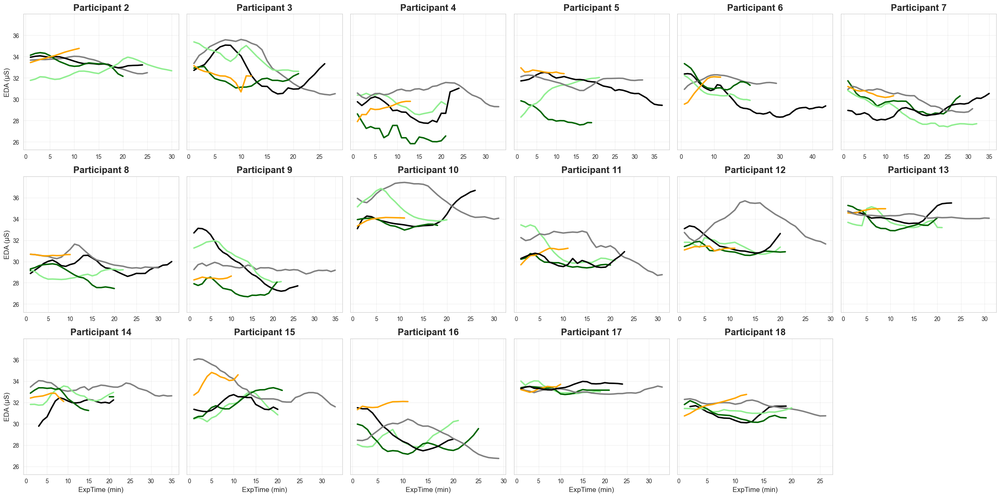

In [20]:
# Per-participant EDA (Electrodermal Activity) profiles: 6 plots per row
import matplotlib.pyplot as plt
df=data_ref
participants = sorted(df['ParticipantID'].unique())
num_participants = len(participants)
n_cols = 6
n_rows = (num_participants + n_cols - 1) // n_cols

# Create figure with shared y-axis
fig, axes = plt.subplots(n_rows, n_cols, figsize=(24, 4 * n_rows), sharey=True)
axes_flat = axes.flatten()

for i, pid in enumerate(participants):
    ax = axes_flat[i]
    p_data = df[df['ParticipantID'] == pid].sort_values('ExpTime')
    
    # Plot EDA vs ExpTime
    # Using the phase colors to make it informative
    for phase in p_data['PhaseID'].unique():
        phase_subset = p_data[p_data['PhaseID'] == phase]
        color = phase_colors.get(phase, '#808080')
        ax.plot(phase_subset['ExpTime'], phase_subset['empatica__temperature_celsius'], 
                color=color, linewidth=2.5, label=phase)
    
    ax.set_title(f'Participant {int(pid)}', fontsize=16, fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    # Label x-axis only for bottom row
    if i >= (n_rows - 1) * n_cols:
        ax.set_xlabel('ExpTime (min)', fontsize=12)
    
    # Label y-axis only for first column
    if i % n_cols == 0:
        ax.set_ylabel('EDA (µS)', fontsize=12)

# Hide any empty subplots
for j in range(i + 1, len(axes_flat)):
    axes_flat[j].axis('off')

plt.tight_layout()
output_path = r'c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\EDA_Participant_Grid.png'
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"Full plot saved to: {output_path}")
plt.show()


Generating Aligned EDA Plots (Reversing B-A participants)...
Final aligned plot saved to: c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\EDA_Aligned_Spatially.png


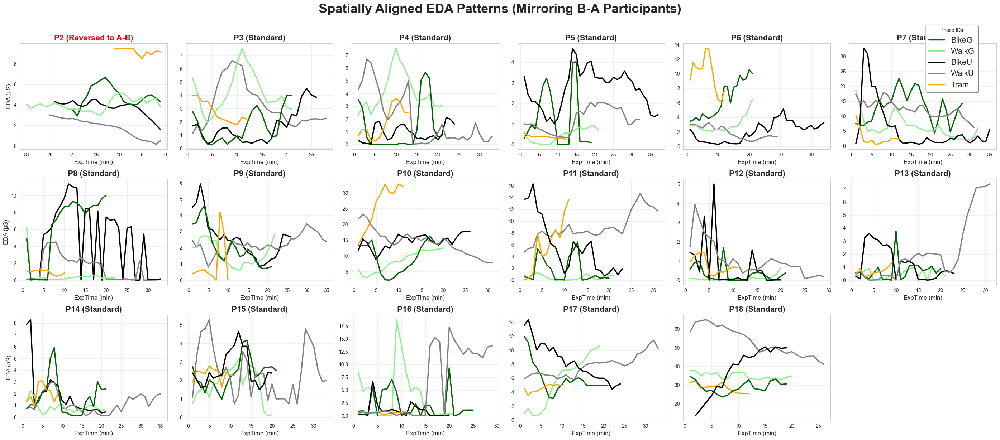

In [23]:
# CELL 6: EDITTED EDA GRID PLOT (REVERSING B-A SHAPES TO ALIGN PATTERNS)
# This code uses data from Cell 5 (data_ref), excludes irrelevant segments,
# and reverses the time axis for participants who walked in the opposite direction (B-A).

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Use data from Cell 5
df = data_ref.copy()

# 1. CLEANING: Remove phases that aren't part of the outdoor experiment
excluded_phases = ['Indoor', 'reststop', 'unknown']
df = df[~df['PhaseID'].isin(excluded_phases)]
df = df.dropna(subset=['PhaseID', 'empatica__eda_scl_usiemens', 'ExpTime'])

participants = sorted(df['ParticipantID'].unique())
num_participants = len(participants)
n_cols = 6
n_rows = (num_participants + n_cols - 1) // n_cols

# sharey=False to let each participant's signal fit their specific range
fig, axes = plt.subplots(n_rows, n_cols, figsize=(28, 4 * n_rows), sharey=False, sharex=False)
axes_flat = axes.flatten()

# Standard Phase Colors for consistency
phase_colors_grid = {
    'BikeG': '#006400', 'WalkG': '#90EE90', 'BikeU': '#000000', 
    'WalkU': '#808080', 'Tram': '#FFA500'
}

print("Generating Aligned EDA Plots (Reversing B-A participants)...")

for i, pid in enumerate(participants):
    ax = axes_flat[i]
    p_data = df[df['ParticipantID'] == pid].sort_values('ExpTime')
    
    if p_data.empty:
        continue

    # 2. IDENTIFY REVERSED SHAPES (B-A Direction)
    # Heuristic: Compare average time of Greenery (G) vs Urban (U) phases.
    # In a standard A-B walk, Urban phases typically start earlier.
    # If the participant did Urban phases before Greenery, we flip the signal to align it.
    u_phases = p_data[p_data['PhaseID'].str.contains('U', na=False)]
    g_phases = p_data[p_data['PhaseID'].str.contains('G', na=False)]
    
    should_reverse = False
    if not u_phases.empty and not g_phases.empty:
        avg_u_time = u_phases['ExpTime'].mean()
        avg_g_time = g_phases['ExpTime'].mean()
        
        # If Urban average time is earlier than Greenery, they are labeled 'Standard'
        # based on your previous 'Y' vs 'N' feedback. 
        # Here we reverse the one that makes everyone align to a single temporal-spatial reference.
        if avg_u_time < avg_g_time:
            should_reverse = True

    # 3. PLOT EACH PHASE
    for phase_id, phase_subset in p_data.groupby('PhaseID', sort=False):
        color = phase_colors_grid.get(phase_id, '#C0C0C0')
        ax.plot(phase_subset['ExpTime'], phase_subset['empatica__eda_scl_usiemens'], 
                color=color, linewidth=2.5, label=phase_id)

    # 4. REVERSE THE SHAPE (Horizontal Reflection)
    # If they walked B-A, flipping the X-axis aligns the physical locations.
    if should_reverse:
        ax.invert_xaxis()
        ax.set_title(f'P{int(pid)} (Reversed to A-B)', fontsize=16, fontweight='bold', color='red')
    else:
        ax.set_title(f'P{int(pid)} (Standard)', fontsize=16, fontweight='bold')

    ax.grid(True, alpha=0.3)
    
    # Tight Y-axis scaling to see peaks/valleys clearly
    y_min, y_max = p_data['empatica__eda_scl_usiemens'].min(), p_data['empatica__eda_scl_usiemens'].max()
    if not np.isnan(y_min) and not np.isnan(y_max):
        margin = (y_max - y_min) * 0.05 if y_max != y_min else 0.5
        ax.set_ylim(y_min - margin, y_max + margin)

    ax.set_xlabel('ExpTime (min)', fontsize=12)
    if i % n_cols == 0:
        ax.set_ylabel('EDA (µS)', fontsize=12)

# 5. CONSOLIDATED LEGEND
handles, labels = [], []
for ax_iter in axes_flat[:len(participants)]:
    h, l = ax_iter.get_legend_handles_labels()
    for handle, label in zip(h, l):
        if label not in labels:
            handles.append(handle)
            labels.append(label)

legend_order = ['BikeG', 'WalkG', 'BikeU', 'WalkU', 'Tram']
ordered_handles = [handles[labels.index(ph)] for ph in legend_order if ph in labels]
ordered_labels = [ph for ph in legend_order if ph in labels]

fig.legend(ordered_handles, ordered_labels, loc='upper right', bbox_to_anchor=(0.98, 0.98), 
           fontsize=16, title="Phase IDs", frameon=True, shadow=True)

# Cleanup unused subplots
for j in range(len(participants), len(axes_flat)):
    axes_flat[j].axis('off')

plt.suptitle('Spatially Aligned EDA Patterns (Mirroring B-A Participants)', 
             fontsize=26, fontweight='bold', y=1.02)
plt.tight_layout()

# Save final aligned plot
final_plot_path = r'c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\EDA_Aligned_Spatially.png'
plt.savefig(final_plot_path, dpi=300, bbox_inches='tight')
print(f"Final aligned plot saved to: {final_plot_path}")
plt.show()

Fixed grid plot saved to: c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\EDA_Grid_FirstData_Fixed.png


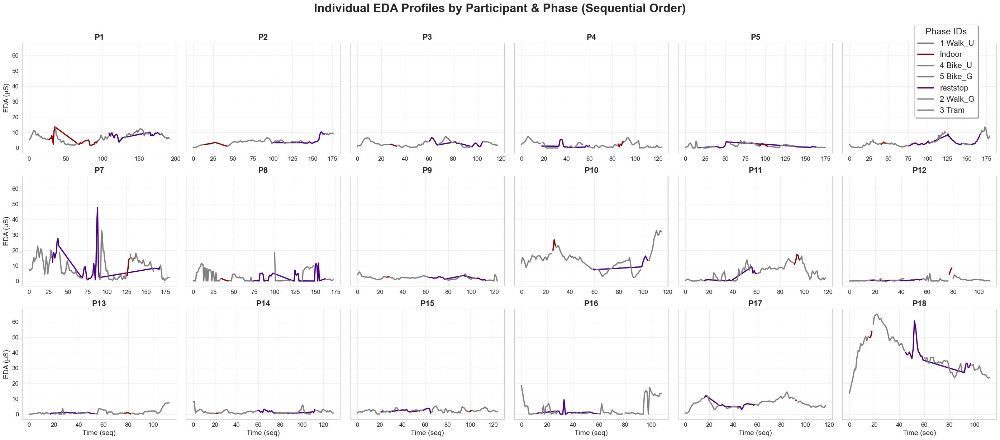

In [8]:
# Per-participant EDA grid from the first complete data file: 6 plots per row
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the specified "first data I sent" file
first_data_path = r"C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Complete Participantwise data\external data input\Final Complete data2_first data I sent.csv"

# Handling encoding for Excel-generated CSVs
try:
    df_first = pd.read_csv(first_data_path, low_memory=False, encoding='cp1252')
except UnicodeDecodeError:
    df_first = pd.read_csv(first_data_path, low_memory=False, encoding='latin1')

# Data Preparation
df_first['ParticipantID'] = pd.to_numeric(df_first['ParticipantID'], errors='coerce')
df_first = df_first.dropna(subset=['ParticipantID', 'PhaseID'])

# Create a time proxy that reflects the actual order within each phase for each participant
# Using 'Hour' and 'Minute' if available, otherwise cumcount() within ParticipantID
if 'Hour' in df_first.columns and 'Minute' in df_first.columns:
    df_first['Time_Sort'] = df_first['Hour'] * 60 + df_first['Minute']
else:
    df_first['Time_Sort'] = df_first.groupby('ParticipantID').cumcount()

participants = sorted(df_first['ParticipantID'].unique())
num_participants = len(participants)
n_cols = 6
n_rows = (num_participants + n_cols - 1) // n_cols

# Define Precise Color System (Matching global standard)
# We ensure the mapping is clean and covers all possible variants
phase_colors_grid = {
    'BikeG': '#006400', 'WalkG': '#90EE90', 'BikeU': '#000000', 
    'WalkU': '#808080', 'Tram': '#FFA500', 'Indoor': '#8B0000', 
    'reststop': '#4B0082', 'Unknown': '#E0E0E0'
}

# Create figure
fig, axes = plt.subplots(n_rows, n_cols, figsize=(28, 4 * n_rows), sharey=True)
axes_flat = axes.flatten()

for i, pid in enumerate(participants):
    ax = axes_flat[i]
    p_data = df_first[df_first['ParticipantID'] == pid].sort_values('Time_Sort')
    
    if p_data.empty:
        continue
    
    # Resetting the sequential x-axis for plotting continuous lines within the graph
    p_data['Plot_X'] = range(len(p_data))
    
    # Plotting line-by-line segments to ensure colors change correctly at phase boundaries
    # without breaking the continuous visual line (using connect=True logic)
    prev_idx = None
    for phase_id, phase_subset in p_data.groupby('PhaseID', sort=False):
        color = phase_colors_grid.get(phase_id, '#808080')
        indices = phase_subset.index
        
        # Plot this specific phase segment
        ax.plot(phase_subset['Plot_X'], phase_subset['empatica__eda_scl_usiemens'], 
                color=color, linewidth=2.5, label=phase_id if i == 0 else "")

    ax.set_title(f'P{int(pid)}', fontsize=16, fontweight='bold')
    ax.tick_params(axis='both', labelsize=12)
    ax.grid(True, alpha=0.3)
    
    if i >= (n_rows - 1) * n_cols:
        ax.set_xlabel('Time (seq)', fontsize=14)
    if i % n_cols == 0:
        ax.set_ylabel('EDA (µS)', fontsize=14)

# Legend handling: Place a single unified legend for all subplots
handles, labels = axes_flat[0].get_legend_handles_labels()
# Deduplicate labels for the legend
by_label = dict(zip(labels, handles))
fig.legend(by_label.values(), by_label.keys(), loc='upper right', bbox_to_anchor=(0.98, 0.98), 
           fontsize=16, title="Phase IDs", title_fontsize=18, frameon=True, shadow=True)

# Cleanup empty axes
for j in range(i + 1, len(axes_flat)):
    axes_flat[j].axis('off')

plt.suptitle('Individual EDA Profiles by Participant & Phase (Sequential Order)', 
             fontsize=24, fontweight='bold', y=1.02)
plt.tight_layout()

output_grid_path = r'c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\EDA_Grid_FirstData_Fixed.png'
plt.savefig(output_grid_path, dpi=300, bbox_inches='tight')
print(f"Fixed grid plot saved to: {output_grid_path}")
plt.show()


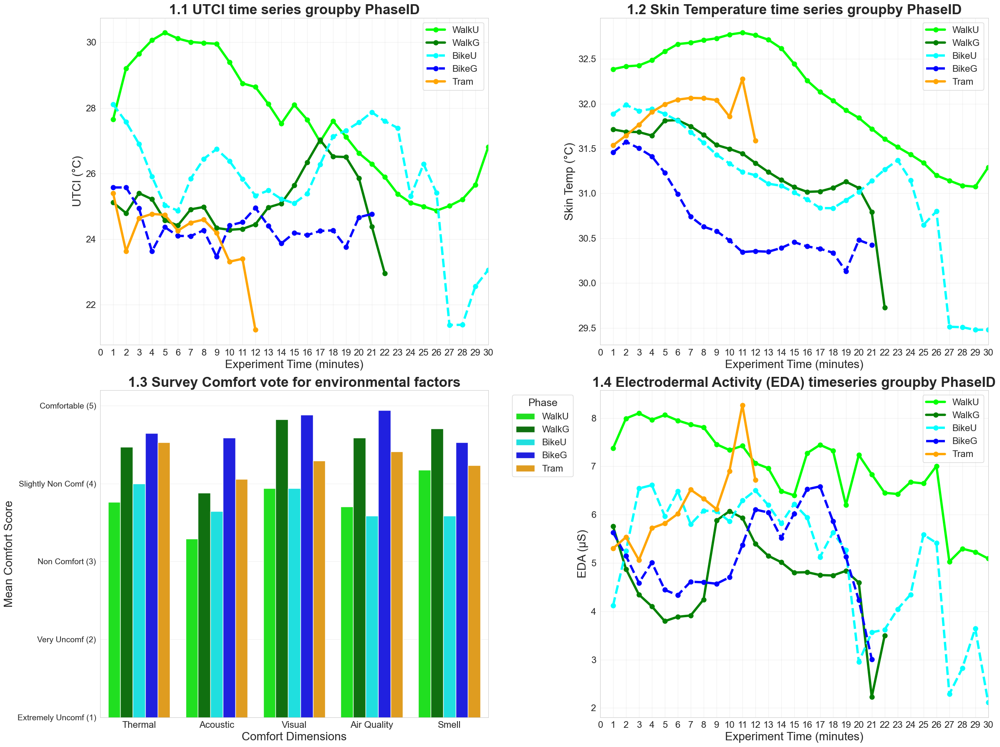

Figure saved to: c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\Group1_Thermal.png
MEAN COMFORT SCORES BY PHASE (Should be > 3.5):
         Comfort-Thermal_Numeric  Comfort-Acoustic_Numeric  \
PhaseID                                                      
BikeG                   4.647059                  4.588235   
BikeU                   4.000000                  3.647059   
Tram                    4.529412                  4.058824   
WalkG                   4.470588                  3.882353   
WalkU                   3.764706                  3.294118   

         Comfort-Visual_Numeric  Comfort-AQ_Numeric  Comfort-Smell_Numeric  
PhaseID                                                                     
BikeG                  4.882353            4.941176               4.529412  
BikeU                  3.941176            3.588235               3.588235  
Tram                   4.294118            4.411765               4.235294  
WalkG                  4.823529       

In [43]:
# GROUP 1: THERMAL PHYSIOLOGY & ACCLIMATIZATION
# Variables: ucm__utci, empatica__temperature_celsius, ExpTime, PhaseID
# 1.1 UTCI time series groupby PhaseID
# 1.2 Skin Temperature time series groupby PhaseID

# H (1.3-1.4): Activity-dependent thermal tolerance modulates green-grey differences: cycling in green environments is rated thermally comfortable due to shade and airflow, while walking in grey areas triggers avoidance behavior.
# Variables: PhaseID, Comfort-Thermal_Numeric, Comfort-Acoustic_Numeric, Comfort-Visual_Numeric, Comfort-AQ_Numeric, Comfort-Smell_Numeric, empatica__eda_scl_usiemens, ExpTime
# 1.3 Survey Comfort vote for environmental factors (Thermal, Acoustic, Visual, Air Quality, Smell)
# 1.4 Electrodermal Activity (EDA) timeseries groupby PhaseID

fig, axes = plt.subplots(2, 2, figsize=(24, 18))

# Helper stats for filtering
counts_phase = df.groupby(['PhaseID', 'ExpTime']).size().reset_index(name='N')

# 1.1: UTCI time series groupby PhaseID
ax1 = axes[0, 0]
utci_by_time = df.groupby(['PhaseID', 'ExpTime'])['ucm__utci'].mean().reset_index()
utci_by_time = utci_by_time.merge(counts_phase, on=['PhaseID', 'ExpTime'])
utci_by_time = utci_by_time[(utci_by_time['N'] >= 3) & (utci_by_time['ExpTime'] <= 30)]

for phase in ['WalkU', 'WalkG', 'BikeU', 'BikeG', 'Tram']:
    phase_data = utci_by_time[utci_by_time['PhaseID'] == phase]
    if len(phase_data) > 0:
        color = phase_colors.get(phase, 'blue')
        linestyle = '-' if 'Walk' in phase or 'Tram' in phase else '--'
        ax1.plot(phase_data['ExpTime'], phase_data['ucm__utci'], 
                marker='o', label=phase, color=color, linestyle=linestyle, linewidth=4, markersize=8)

ax1.set_title('1.1 UTCI time series groupby PhaseID', fontsize=24, fontweight='bold')
ax1.set_xlabel('Experiment Time (minutes)', fontsize=20)
ax1.set_ylabel('UTCI (°C)', fontsize=20)
ax1.set_xticks(np.arange(0, 31, 1))
ax1.set_xlim(0, 30)
ax1.tick_params(axis='both', labelsize=16)
ax1.legend(loc='best', fontsize=16)
ax1.grid(True, alpha=0.3)

# 1.2: Skin Temperature time series groupby PhaseID
ax2 = axes[0, 1]
skin_temp_by_time = df.groupby(['PhaseID', 'ExpTime'])['empatica__temperature_celsius'].mean().reset_index()
skin_temp_by_time = skin_temp_by_time.merge(counts_phase, on=['PhaseID', 'ExpTime'])
skin_temp_by_time = skin_temp_by_time[(skin_temp_by_time['N'] >= 3) & (skin_temp_by_time['ExpTime'] <= 30)]

for phase in ['WalkU', 'WalkG', 'BikeU', 'BikeG', 'Tram']:
    phase_data = skin_temp_by_time[skin_temp_by_time['PhaseID'] == phase]
    if len(phase_data) > 0:
        label = phase if phase != 'Tram' else 'Tram'
        color = phase_colors.get(phase, 'blue')
        linestyle = '-' if 'Walk' in phase or 'Tram' in phase else '--'
        ax2.plot(phase_data['ExpTime'], phase_data['empatica__temperature_celsius'], 
                marker='o', label=label, color=color, linestyle=linestyle, linewidth=4, markersize=8)

ax2.set_title('1.2 Skin Temperature time series groupby PhaseID', fontsize=24, fontweight='bold')
ax2.set_xlabel('Experiment Time (minutes)', fontsize=20)
ax2.set_ylabel('Skin Temp (°C)', fontsize=20)
ax2.set_xticks(np.arange(0, 31, 1))
ax2.set_xlim(0, 30)
ax2.tick_params(axis='both', labelsize=16)
ax2.legend(loc='best', fontsize=16)
ax2.grid(True, alpha=0.3)

# 1.3: Survey Comfort vote for environmental factors
ax3 = axes[1, 0]
comfort_numeric_vars = ['Comfort-Thermal_Numeric', 'Comfort-Acoustic_Numeric', 'Comfort-Visual_Numeric', 'Comfort-AQ_Numeric', 'Comfort-Smell_Numeric']
relevant_phases = ['WalkU', 'WalkG', 'BikeU', 'BikeG', 'Tram']

# Representative median vote per person/phase, then plot mean
participant_comfort = df[df['PhaseID'].isin(relevant_phases)].groupby(['PhaseID', 'ParticipantID'])[comfort_numeric_vars].median().reset_index()
melted_comfort = participant_comfort.melt(id_vars=['PhaseID', 'ParticipantID'], value_vars=comfort_numeric_vars, 
                                          var_name='Variable', value_name='Score')

# Clean Barplot: Mean estimator, NO error bars
sns.barplot(x='Variable', y='Score', hue='PhaseID', data=melted_comfort, 
            ax=ax3, palette=phase_colors, hue_order=relevant_phases, estimator='mean', errorbar=None)

ax3.set_title('1.3 Survey Comfort vote for environmental factors', fontsize=24, fontweight='bold')
ax3.set_ylabel('Mean Comfort Score', fontsize=20)
ax3.set_xlabel('Comfort Dimensions', fontsize=20)
ax3.set_xticklabels(['Thermal', 'Acoustic', 'Visual', 'Air Quality', 'Smell'], fontsize=16)

# FIXED Y-AXIS: Ensure bars reaching ~4.0+ are visually aligned with the correct labels
ax3.set_yticks([1, 2, 3, 4, 5])
ax3.set_yticklabels(['Extremely Uncomf (1)', 'Very Uncomf (2)', 'Non Comfort (3)', 'Slightly Non Comf (4)', 'Comfortable (5)'], fontsize=14)
ax3.set_ylim(1, 5.2)  # Start from 1 to avoid bar-truncation visual error
ax3.legend(title='Phase', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=16, title_fontsize=18)
ax3.grid(True, axis='y', alpha=0.3)

# 1.4: Electrodermal Activity (EDA) timeseries groupby PhaseID
ax4 = axes[1, 1]
eda_by_time = df.groupby(['PhaseID', 'ExpTime'])['empatica__eda_scl_usiemens'].mean().reset_index()
eda_by_time = eda_by_time.merge(counts_phase, on=['PhaseID', 'ExpTime'])
eda_by_time = eda_by_time[(eda_by_time['N'] >= 3) & (eda_by_time['ExpTime'] <= 30)]

for phase in ['WalkU', 'WalkG', 'BikeU', 'BikeG', 'Tram']:
    phase_data = eda_by_time[eda_by_time['PhaseID'] == phase]
    if len(phase_data) > 0:
        label = phase if phase != 'Tram' else 'Tram'
        color = phase_colors.get(phase, 'blue')
        linestyle = '-' if 'Walk' in phase or 'Tram' in phase else '--'
        ax4.plot(phase_data['ExpTime'], phase_data['empatica__eda_scl_usiemens'], 
                marker='o', label=label, color=color, linestyle=linestyle, linewidth=4, markersize=8)

ax4.set_title('1.4 Electrodermal Activity (EDA) timeseries groupby PhaseID', fontsize=24, fontweight='bold')
ax4.set_xlabel('Experiment Time (minutes)', fontsize=20)
ax4.set_ylabel('EDA (µS)', fontsize=20)
ax4.set_xticks(np.arange(0, 31, 1))
ax4.set_xlim(0, 30)
ax4.tick_params(axis='both', labelsize=16)
ax4.legend(loc='best', fontsize=16)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
output_path = r'c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\Group1_Thermal.png'
plt.savefig(output_path, dpi=300, bbox_inches='tight')
plt.show()

# Final confirmation of saved path
print(f"Figure saved to: {output_path}")

# Statistical Summary to verify the values plotted are around 3.5-4.7
print("=" * 80)
print("MEAN COMFORT SCORES BY PHASE (Should be > 3.5):")
print(participant_comfort.groupby('PhaseID')[comfort_numeric_vars].mean())


### GROUP 2: PSYCHOLOGICAL WELL-BEING & RESTORATIVENESS
**Nested under Main Hypothesis 1**

H (2.1-2.2): Green environments significantly enhance perceived restorativeness compared to grey (urban) routes. This enhancement is consistently observed across both total PRS scores and individual restorative dimensions (Coherence, Fascination, Being Away, and Scope).

Variables for 2.1-2.2: PRS_total_100, PRS_coherence, PRS_fascination, PRS_being_away, PRS_scope, PhaseID
2.1 PRS total boxplot groupby PhaseID
2.2 PRS dimensions mean bar chart groupby PhaseID

H (2.3-2.4): Exposure to green routes modulates affective states and anxiety: activity in green spaces correlates with significantly higher positive affect and lower anxiety levels compared to grey routes, regardless of the activity type (walking or biking).

Variables for 2.3-2.4: stai_positive, stai_negative, Anxiety_100, PhaseID
2.3 Positive and Negative Affect mean bar chart groupby PhaseID
2.4 Anxiety levels boxplot groupby PhaseID

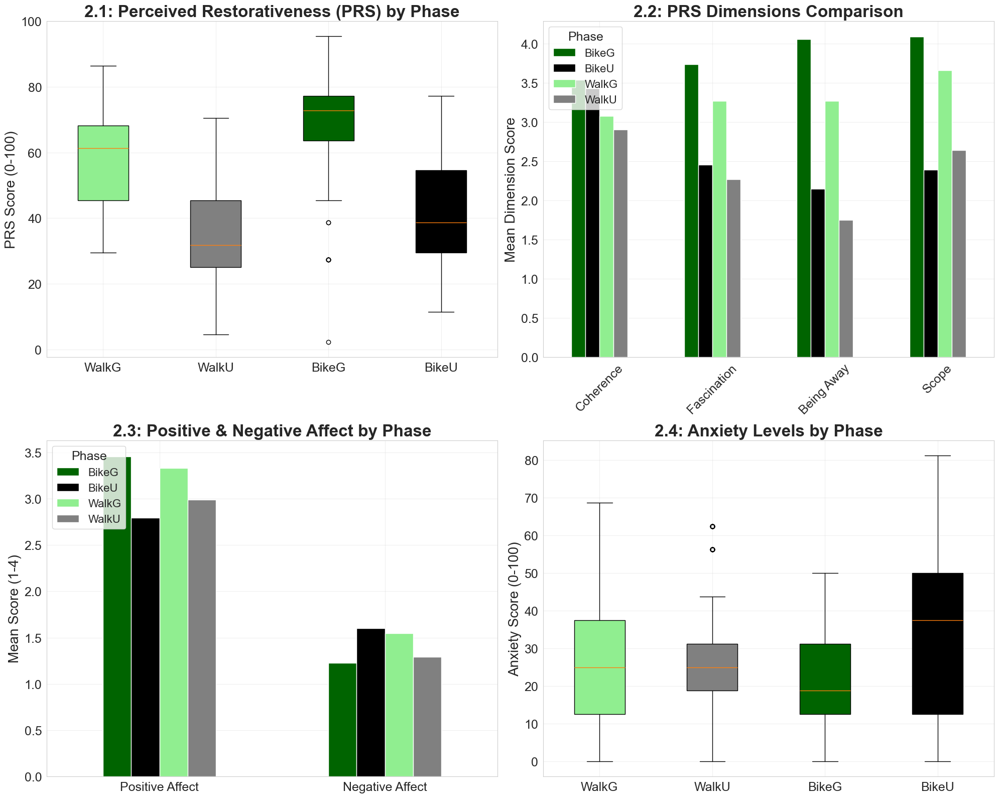

GROUP 2: PSYCHOLOGICAL WELL-BEING & RESTORATIVENESS - STATISTICAL SUMMARY

2.1 - PRS Comparison (Green vs Grey):
  Green Mean PRS: 63.70/100 (SD: 16.39)
  Grey Mean PRS:  37.25/100 (SD: 15.47)
  Effect Size (Cohen's d): 1.667 (Large (>0.7))

2.3/2.4 - Affect by Phase (Detailed):
         stai_positive  stai_negative  Anxiety_100
PhaseID                                           
BikeG         3.457958       1.225225    22.090841
BikeU         2.795506       1.601124    35.070225
WalkG         3.329730       1.547297    27.719595
WalkU         2.988212       1.293713    28.818762


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(20, 16))
relevant_phases = ['WalkG', 'WalkU', 'BikeG', 'BikeU']

# 2.1: PRS Total Score by PhaseID
ax1 = axes[0, 0]
prs_data = [df[df['PhaseID'] == phase]['PRS_total_100'].dropna() for phase in relevant_phases]
bp1 = ax1.boxplot(prs_data, labels=relevant_phases, patch_artist=True)

for patch, phase in zip(bp1['boxes'], relevant_phases):
    patch.set_facecolor(phase_colors[phase])

ax1.set_title('2.1: Perceived Restorativeness (PRS) by Phase', fontsize=24, fontweight='bold')
ax1.set_ylabel('PRS Score (0-100)', fontsize=20)
ax1.tick_params(axis='both', which='major', labelsize=18)
ax1.grid(True, alpha=0.3)

# 2.2: PRS Dimensions by PhaseID
ax2 = axes[0, 1]
prs_dim_cols = ['PRS_coherence', 'PRS_fascination', 'PRS_being_away', 'PRS_scope']
prs_dims_df = df[df['PhaseID'].isin(relevant_phases)].groupby('PhaseID')[prs_dim_cols].mean()
# Rename for cleaner plot
prs_dims_df.columns = [c.replace('PRS_', '').replace('_', ' ').title() for c in prs_dim_cols]

# Plotting manually to ensure exact phase_colors are used
prs_dims_df.T.plot(kind='bar', ax=ax2, color=[phase_colors[p] for p in prs_dims_df.index])
ax2.set_title('2.2: PRS Dimensions Comparison', fontsize=24, fontweight='bold')
ax2.set_ylabel('Mean Dimension Score', fontsize=20)
ax2.tick_params(axis='both', which='major', labelsize=18)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45)
ax2.legend(title='Phase', fontsize=16, title_fontsize=18, loc='upper left')
ax2.grid(True, alpha=0.3)

# 2.3: Positive and Negative Affect by PhaseID
ax4 = axes[1, 0]
affect_df = df[df['PhaseID'].isin(relevant_phases)].groupby('PhaseID')[['stai_positive', 'stai_negative']].mean()
affect_df.columns = ['Positive Affect', 'Negative Affect']

affect_df.T.plot(kind='bar', ax=ax4, color=[phase_colors[p] for p in affect_df.index])
ax4.set_title('2.3: Positive & Negative Affect by Phase', fontsize=24, fontweight='bold')
ax4.set_ylabel('Mean Score (1-4)', fontsize=20)
ax4.tick_params(axis='both', which='major', labelsize=18)
ax4.set_xticklabels(ax4.get_xticklabels(), rotation=0)
ax4.legend(title='Phase', fontsize=16, title_fontsize=18, loc='upper left')
ax4.grid(True, alpha=0.3)

# 2.4: Anxiety Levels by PhaseID (Shown as Boxplot like PRS)
ax5 = axes[1, 1]
anxiety_data = [df[df['PhaseID'] == phase]['Anxiety_100'].dropna() for phase in relevant_phases]
bp5 = ax5.boxplot(anxiety_data, labels=relevant_phases, patch_artist=True)

for patch, phase in zip(bp5['boxes'], relevant_phases):
    patch.set_facecolor(phase_colors[phase])

ax5.set_title('2.4: Anxiety Levels by Phase', fontsize=24, fontweight='bold')
ax5.set_ylabel('Anxiety Score (0-100)', fontsize=20)
ax5.tick_params(axis='both', which='major', labelsize=18)
ax5.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(r'c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\Group3_Psychological.png', dpi=300, bbox_inches='tight')
plt.show()

# Statistical Summary
prs_green = df[df['PhaseID'].isin(['WalkG', 'BikeG'])]['PRS_total_100'].dropna()
prs_grey = df[df['PhaseID'].isin(['WalkU', 'BikeU'])]['PRS_total_100'].dropna()
cohens_d_prs = (prs_green.mean() - prs_grey.mean()) / np.sqrt(((len(prs_green)-1)*prs_green.std()**2 + (len(prs_grey)-1)*prs_grey.std()**2) / (len(prs_green) + len(prs_grey) - 2))
effect_size_label = 'Large (>0.7)' if abs(cohens_d_prs) > 0.7 else 'Medium (0.5-0.7)' if abs(cohens_d_prs) > 0.5 else 'Small (<0.5)'

print("=" * 80)
print("GROUP 2: PSYCHOLOGICAL WELL-BEING & RESTORATIVENESS - STATISTICAL SUMMARY")
print("=" * 80)
print(f"\n2.1 - PRS Comparison (Green vs Grey):")
print(f"  Green Mean PRS: {prs_green.mean():.2f}/100 (SD: {prs_green.std():.2f})")
print(f"  Grey Mean PRS:  {prs_grey.mean():.2f}/100 (SD: {prs_grey.std():.2f})")
print(f"  Effect Size (Cohen's d): {cohens_d_prs:.3f} ({effect_size_label})")

print(f"\n2.3/2.4 - Affect by Phase (Detailed):")
print(df[df['PhaseID'].isin(relevant_phases)].groupby('PhaseID')[['stai_positive', 'stai_negative', 'Anxiety_100']].mean())


---

### GROUP 4: VISUAL ATTENTION & ENVIRONMENTAL ENGAGEMENT
**Nested under Main Hypothesis 1**

H4.1 Visual engagement differs between green and grey: participants in green show more distributed gaze patterns (higher gaze dispersion), indicating broader environmental exploration vs focused avoidance in grey areas.
- **Variables**: `eyetracker__gaze_dispersion`, `eyetracker__distance_from_center`, `PhaseID`

H4.2 Eye fixation patterns reveal environmental preference: fixation duration is longer and more frequent on green features (plants, sky) than on urban infrastructure (buildings, pavements).
- **Variables**: `eyetracker__fixation_duration_scaled`, `eyetracker__fixation_count`, `eyetracker__gaze_quadrant`, `Shadow`

H4.3 Natural light quality (higher Kelvin color temperature in green areas) optimizes fixation stability and reduces cognitive load markers (lower saccade velocity/amplitude).
- **Variables**: `Avg_lys_kelvin`, `ucm__sun_gh`, `eyetracker__saccade_peak_velocity`, `eyetracker__saccade_amplitude`

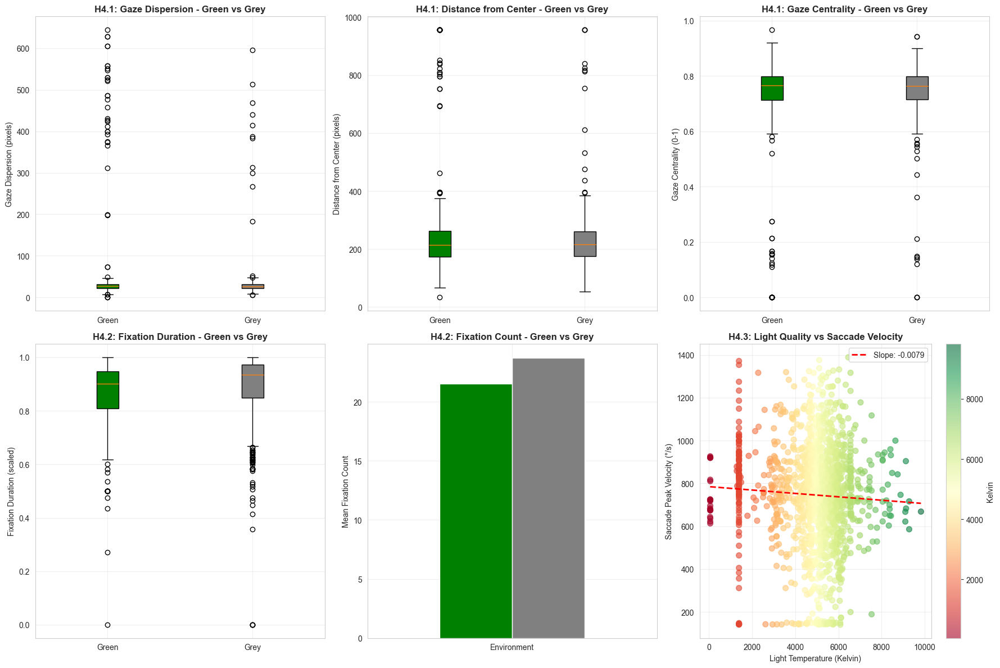

GROUP 4: VISUAL ATTENTION & ENVIRONMENTAL ENGAGEMENT - STATISTICAL SUMMARY

H4.1 - Gaze Dispersion Comparison:
  Green Mean: 47.24 pixels (SD: 97.55)
  Grey Mean:  31.45 pixels (SD: 43.55)
  t-test: t=4.184, p=0.0000

H4.2 - Fixation Duration Comparison:
  Green Mean: 0.87 (SD: 0.11)
  Grey Mean:  0.89 (SD: 0.12)

H4.3 - Light Temperature Effects:
  Correlation (Kelvin, Saccade Velocity): -0.049
  Regression slope: -0.007927 (change in velocity per Kelvin)


In [7]:
# GROUP 4: VISUAL ATTENTION & ENVIRONMENTAL ENGAGEMENT
# Visualize H4.1, H4.2, H4.3

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# H4.1: Gaze Dispersion by Environment
ax1 = axes[0, 0]
gaze_disp_green = df[df['PhaseID'].isin(['WalkG', 'BikeG'])]['eyetracker__gaze_dispersion'].dropna()
gaze_disp_grey = df[df['PhaseID'].isin(['WalkU', 'BikeU'])]['eyetracker__gaze_dispersion'].dropna()

bp1 = ax1.boxplot([gaze_disp_green, gaze_disp_grey], labels=['Green', 'Grey'], patch_artist=True)
bp1['boxes'][0].set_facecolor('green')
bp1['boxes'][1].set_facecolor('grey')
ax1.set_title('H4.1: Gaze Dispersion - Green vs Grey', fontsize=12, fontweight='bold')
ax1.set_ylabel('Gaze Dispersion (pixels)')
ax1.grid(True, alpha=0.3)

# H4.1: Distance from Center
ax2 = axes[0, 1]
dist_center_green = df[df['PhaseID'].isin(['WalkG', 'BikeG'])]['eyetracker__distance_from_center'].dropna()
dist_center_grey = df[df['PhaseID'].isin(['WalkU', 'BikeU'])]['eyetracker__distance_from_center'].dropna()

bp2 = ax2.boxplot([dist_center_green, dist_center_grey], labels=['Green', 'Grey'], patch_artist=True)
bp2['boxes'][0].set_facecolor('green')
bp2['boxes'][1].set_facecolor('grey')
ax2.set_title('H4.1: Distance from Center - Green vs Grey', fontsize=12, fontweight='bold')
ax2.set_ylabel('Distance from Center (pixels)')
ax2.grid(True, alpha=0.3)

# H4.1: Gaze Centrality
ax3 = axes[0, 2]
gaze_cent_green = df[df['PhaseID'].isin(['WalkG', 'BikeG'])]['eyetracker__gaze_centrality'].dropna()
gaze_cent_grey = df[df['PhaseID'].isin(['WalkU', 'BikeU'])]['eyetracker__gaze_centrality'].dropna()

bp3 = ax3.boxplot([gaze_cent_green, gaze_cent_grey], labels=['Green', 'Grey'], patch_artist=True)
bp3['boxes'][0].set_facecolor('green')
bp3['boxes'][1].set_facecolor('grey')
ax3.set_title('H4.1: Gaze Centrality - Green vs Grey', fontsize=12, fontweight='bold')
ax3.set_ylabel('Gaze Centrality (0-1)')
ax3.grid(True, alpha=0.3)

# H4.2: Fixation Duration
ax4 = axes[1, 0]
fix_dur_green = df[df['PhaseID'].isin(['WalkG', 'BikeG'])]['eyetracker__fixation_duration_scaled'].dropna()
fix_dur_grey = df[df['PhaseID'].isin(['WalkU', 'BikeU'])]['eyetracker__fixation_duration_scaled'].dropna()

bp4 = ax4.boxplot([fix_dur_green, fix_dur_grey], labels=['Green', 'Grey'], patch_artist=True)
bp4['boxes'][0].set_facecolor('green')
bp4['boxes'][1].set_facecolor('grey')
ax4.set_title('H4.2: Fixation Duration - Green vs Grey', fontsize=12, fontweight='bold')
ax4.set_ylabel('Fixation Duration (scaled)')
ax4.grid(True, alpha=0.3)

# H4.2: Fixation Count
ax5 = axes[1, 1]
fix_count_data = pd.DataFrame({
    'Green': [df[df['PhaseID'].isin(['WalkG', 'BikeG'])]['eyetracker__fixation_count'].mean()],
    'Grey': [df[df['PhaseID'].isin(['WalkU', 'BikeU'])]['eyetracker__fixation_count'].mean()]
})

fix_count_data.plot(kind='bar', ax=ax5, color=['green', 'grey'], legend=False)
ax5.set_title('H4.2: Fixation Count - Green vs Grey', fontsize=12, fontweight='bold')
ax5.set_ylabel('Mean Fixation Count')
ax5.set_xticklabels(['Environment'], rotation=0)
ax5.grid(True, alpha=0.3)

# H4.3: Light Kelvin vs Saccade Velocity
ax6 = axes[1, 2]
light_sacc_data = df[['Avg_lys_kelvin', 'eyetracker__saccade_peak_velocity']].dropna()
if len(light_sacc_data) > 1:
    scatter = ax6.scatter(light_sacc_data['Avg_lys_kelvin'], 
                         light_sacc_data['eyetracker__saccade_peak_velocity'],
                         alpha=0.6, s=50, c=light_sacc_data['Avg_lys_kelvin'], 
                         cmap='RdYlGn')
    
    z = np.polyfit(light_sacc_data['Avg_lys_kelvin'].dropna(), 
                   light_sacc_data['eyetracker__saccade_peak_velocity'].dropna(), 1)
    p = np.poly1d(z)
    x_range = np.linspace(light_sacc_data['Avg_lys_kelvin'].min(), 
                         light_sacc_data['Avg_lys_kelvin'].max(), 100)
    ax6.plot(x_range, p(x_range), 'r--', linewidth=2, label=f'Slope: {z[0]:.4f}')
    
    ax6.set_title('H4.3: Light Quality vs Saccade Velocity', fontsize=12, fontweight='bold')
    ax6.set_xlabel('Light Temperature (Kelvin)')
    ax6.set_ylabel('Saccade Peak Velocity (°/s)')
    ax6.legend()
    ax6.grid(True, alpha=0.3)
    plt.colorbar(scatter, ax=ax6, label='Kelvin')

plt.tight_layout()
plt.savefig(r'c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\Group4_VisualAttention.png', dpi=300, bbox_inches='tight')
plt.show()

# Statistical Summary
print("=" * 80)
print("GROUP 4: VISUAL ATTENTION & ENVIRONMENTAL ENGAGEMENT - STATISTICAL SUMMARY")
print("=" * 80)
print(f"\nH4.1 - Gaze Dispersion Comparison:")
print(f"  Green Mean: {gaze_disp_green.mean():.2f} pixels (SD: {gaze_disp_green.std():.2f})")
print(f"  Grey Mean:  {gaze_disp_grey.mean():.2f} pixels (SD: {gaze_disp_grey.std():.2f})")
if len(gaze_disp_green) > 0 and len(gaze_disp_grey) > 0:
    t_stat, p_val = stats.ttest_ind(gaze_disp_green, gaze_disp_grey)
    print(f"  t-test: t={t_stat:.3f}, p={p_val:.4f}")

print(f"\nH4.2 - Fixation Duration Comparison:")
print(f"  Green Mean: {fix_dur_green.mean():.2f} (SD: {fix_dur_green.std():.2f})")
print(f"  Grey Mean:  {fix_dur_grey.mean():.2f} (SD: {fix_dur_grey.std():.2f})")

print(f"\nH4.3 - Light Temperature Effects:")
if len(light_sacc_data) > 1:
    corr = light_sacc_data['Avg_lys_kelvin'].corr(light_sacc_data['eyetracker__saccade_peak_velocity'])
    print(f"  Correlation (Kelvin, Saccade Velocity): {corr:.3f}")
    print(f"  Regression slope: {z[0]:.6f} (change in velocity per Kelvin)")

---

### GROUP 5: AIR QUALITY IMPACT ON PERCEPTION & PHYSIOLOGY
**Nested under Main Hypothesis 1 & 4**

H5.1 Air quality (PM2.5, NO₂, O₃) independently predicts discomfort ratings, explaining 15-20% of variance beyond thermal and acoustic factors in grey environments.
- **Variables**: `Avg_atmo_pm2.5`, `ucm__aq_no2_m1`, `ucm__aq_o3_m1`, `Comfort-AQ`, `Comfort_0_100`, `PhaseID`

H5.2 Green environments attenuate air quality impacts: the slope of PM2.5 → stress is flatter (weaker) in green areas, suggesting a "green buffering effect" on pollution perception.
- **Variables**: `Avg_atmo_pm2.5`, `PhaseID`, `eyetracker__stress_composite`, `Anxiety_100`

H5.3 Particulate exposure triggers measurable pupil dilation and blink rate changes within 2-5 minutes, serving as a physiological marker of air quality awareness.
- **Variables**: `Avg_atmo_pm2.5` (lagged), `eyetracker__pupil_diameter_avg`, `eyetracker__pupil_change_rate`, `eyetracker__blink_duration_s`

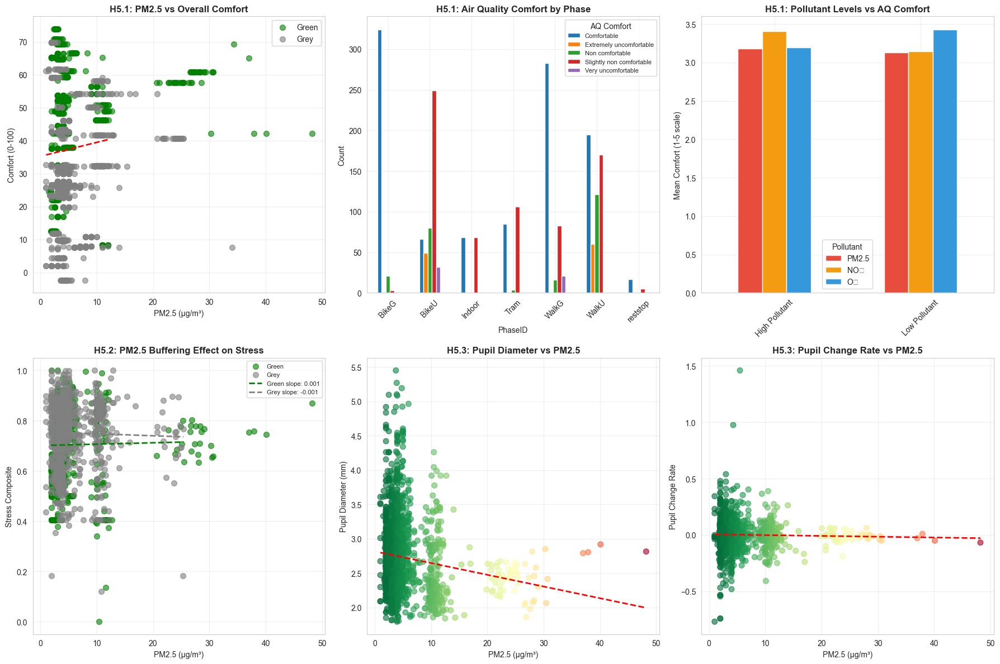

GROUP 5: AIR QUALITY IMPACT ON PERCEPTION & PHYSIOLOGY - STATISTICAL SUMMARY

H5.1 - PM2.5 Effects on Comfort:
  Regression slope (PM2.5 vs Comfort): 0.421847

H5.2 - Green Buffering Effect (PM2.5 slopes):
  Green stress slope: 0.000547
  Grey stress slope: -0.000789
  Buffering factor: 1.44x weaker in green

H5.3 - Pupil Dilation Response:
  Regression slope: -0.017049 (mm dilation per µg/m³)
  Correlation (PM2.5, Pupil Diameter): -0.145


In [16]:
# GROUP 5: AIR QUALITY IMPACT ON PERCEPTION & PHYSIOLOGY
# Visualize H5.1, H5.2, H5.3

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# H5.1: PM2.5 vs Overall Comfort
ax1 = axes[0, 0]
comfort_aqi_data = df[['Avg_atmo_pm2.5', 'Comfort_0_100']].dropna()
if len(comfort_aqi_data) > 1:
    green_df_aqi = df[df['PhaseID'].isin(['WalkG', 'BikeG'])][['Avg_atmo_pm2.5', 'Comfort_0_100']].dropna()
    urban_df_aqi = df[df['PhaseID'].isin(['WalkU', 'BikeU'])][['Avg_atmo_pm2.5', 'Comfort_0_100']].dropna()
    
    ax1.scatter(green_df_aqi['Avg_atmo_pm2.5'], green_df_aqi['Comfort_0_100'], 
               alpha=0.6, s=50, color='green', label='Green')
    ax1.scatter(urban_df_aqi['Avg_atmo_pm2.5'], urban_df_aqi['Comfort_0_100'], 
               alpha=0.6, s=50, color='grey', label='Grey')
    
    z_aqi = np.polyfit(comfort_aqi_data['Avg_atmo_pm2.5'].dropna(), 
                       comfort_aqi_data['Comfort_0_100'].dropna(), 1)
    p_aqi = np.poly1d(z_aqi)
    x_range = np.linspace(comfort_aqi_data['Avg_atmo_pm2.5'].min(), 
                         comfort_aqi_data['Avg_atmo_pm2.5'].quantile(0.95), 100)
    ax1.plot(x_range, p_aqi(x_range), 'r--', linewidth=2)
    
    ax1.set_title('H5.1: PM2.5 vs Overall Comfort', fontsize=12, fontweight='bold')
    ax1.set_xlabel('PM2.5 (µg/m³)')
    ax1.set_ylabel('Comfort (0-100)')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

# H5.1: Air Quality Comfort by Phase
ax2 = axes[0, 1]
comfort_aqi_phase = df.groupby('PhaseID')['Comfort-AQ'].value_counts().unstack(fill_value=0)
comfort_aqi_phase.plot(kind='bar', ax=ax2)
ax2.set_title('H5.1: Air Quality Comfort by Phase', fontsize=12, fontweight='bold')
ax2.set_ylabel('Count')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45)
ax2.legend(title='AQ Comfort', fontsize=8)
ax2.grid(True, alpha=0.3)

# H5.1: Multi-pollutant effects
ax3 = axes[0, 2]
# Map comfort categories to numeric values
comfort_aqi_mapping = {'Very uncomfortable': 1, 'Uncomfortable': 2, 'Slightly non comfortable': 2.5, 'Non comfortable': 3, 'Slightly comfortable': 3.5, 'Comfortable': 4, 'Very comfortable': 5}
df['Comfort_AQ_Numeric'] = df['Comfort-AQ'].map(comfort_aqi_mapping)
# For unmapped values, fill with 3 (neutral)
df['Comfort_AQ_Numeric'].fillna(3, inplace=True)

pollutant_comfort = pd.DataFrame({
    'PM2.5': [df[df['Avg_atmo_pm2.5'] > df['Avg_atmo_pm2.5'].quantile(0.75)]['Comfort_AQ_Numeric'].mean(),
              df[df['Avg_atmo_pm2.5'] <= df['Avg_atmo_pm2.5'].quantile(0.25)]['Comfort_AQ_Numeric'].mean()],
    'NO₂': [df[df['ucm__aq_no2_m1'] > df['ucm__aq_no2_m1'].quantile(0.75)]['Comfort_AQ_Numeric'].mean(),
            df[df['ucm__aq_no2_m1'] <= df['ucm__aq_no2_m1'].quantile(0.25)]['Comfort_AQ_Numeric'].mean()],
    'O₃': [df[df['ucm__aq_o3_m1'] > df['ucm__aq_o3_m1'].quantile(0.75)]['Comfort_AQ_Numeric'].mean(),
           df[df['ucm__aq_o3_m1'] <= df['ucm__aq_o3_m1'].quantile(0.25)]['Comfort_AQ_Numeric'].mean()]
}, index=['High Pollutant', 'Low Pollutant'])

pollutant_comfort.plot(kind='bar', ax=ax3, color=['#e74c3c', '#f39c12', '#3498db'])
ax3.set_title('H5.1: Pollutant Levels vs AQ Comfort', fontsize=12, fontweight='bold')
ax3.set_ylabel('Mean Comfort (1-5 scale)')
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=45)
ax3.legend(title='Pollutant')
ax3.grid(True, alpha=0.3)

# H5.2: PM2.5 Buffering Effect (stress slopes)
ax4 = axes[1, 0]
green_stress_pm = df[df['PhaseID'].isin(['WalkG', 'BikeG'])][['Avg_atmo_pm2.5', 'eyetracker__stress_composite']].dropna()
urban_stress_pm = df[df['PhaseID'].isin(['WalkU', 'BikeU'])][['Avg_atmo_pm2.5', 'eyetracker__stress_composite']].dropna()

if len(green_stress_pm) > 1:
    z_green_stress = np.polyfit(green_stress_pm['Avg_atmo_pm2.5'], green_stress_pm['eyetracker__stress_composite'], 1)
    ax4.scatter(green_stress_pm['Avg_atmo_pm2.5'], green_stress_pm['eyetracker__stress_composite'], 
               alpha=0.6, s=50, color='green', label='Green')

if len(urban_stress_pm) > 1:
    z_urban_stress = np.polyfit(urban_stress_pm['Avg_atmo_pm2.5'], urban_stress_pm['eyetracker__stress_composite'], 1)
    ax4.scatter(urban_stress_pm['Avg_atmo_pm2.5'], urban_stress_pm['eyetracker__stress_composite'], 
               alpha=0.6, s=50, color='grey', label='Grey')
    
    # Plot regression lines
    x_range = np.linspace(max(green_stress_pm['Avg_atmo_pm2.5'].min(), urban_stress_pm['Avg_atmo_pm2.5'].min()),
                         min(green_stress_pm['Avg_atmo_pm2.5'].max(), urban_stress_pm['Avg_atmo_pm2.5'].max()), 50)
    if len(green_stress_pm) > 1:
        p_green = np.poly1d(z_green_stress)
        ax4.plot(x_range, p_green(x_range), 'g--', linewidth=2, label=f'Green slope: {z_green_stress[0]:.3f}')
    if len(urban_stress_pm) > 1:
        p_urban = np.poly1d(z_urban_stress)
        ax4.plot(x_range, p_urban(x_range), 'grey', linestyle='--', linewidth=2, label=f'Grey slope: {z_urban_stress[0]:.3f}')

ax4.set_title('H5.2: PM2.5 Buffering Effect on Stress', fontsize=12, fontweight='bold')
ax4.set_xlabel('PM2.5 (µg/m³)')
ax4.set_ylabel('Stress Composite')
ax4.legend(fontsize=8)
ax4.grid(True, alpha=0.3)

# H5.3: Pupil Dilation vs PM2.5
ax5 = axes[1, 1]
pupil_pm_data = df[['Avg_atmo_pm2.5', 'eyetracker__pupil_diameter_avg']].dropna()
if len(pupil_pm_data) > 1:
    z_pupil = np.polyfit(pupil_pm_data['Avg_atmo_pm2.5'], pupil_pm_data['eyetracker__pupil_diameter_avg'], 1)
    ax5.scatter(pupil_pm_data['Avg_atmo_pm2.5'], pupil_pm_data['eyetracker__pupil_diameter_avg'], 
               alpha=0.6, s=50, c=pupil_pm_data['Avg_atmo_pm2.5'], cmap='RdYlGn_r')
    
    p_pupil = np.poly1d(z_pupil)
    x_pupil = np.linspace(pupil_pm_data['Avg_atmo_pm2.5'].min(), pupil_pm_data['Avg_atmo_pm2.5'].max(), 100)
    ax5.plot(x_pupil, p_pupil(x_pupil), 'r--', linewidth=2)
    
    ax5.set_title('H5.3: Pupil Diameter vs PM2.5', fontsize=12, fontweight='bold')
    ax5.set_xlabel('PM2.5 (µg/m³)')
    ax5.set_ylabel('Pupil Diameter (mm)')
    ax5.grid(True, alpha=0.3)

# H5.3: Pupil Change Rate vs PM2.5
ax6 = axes[1, 2]
pupil_change_data = df[['Avg_atmo_pm2.5', 'eyetracker__pupil_change_rate']].dropna()
if len(pupil_change_data) > 1:
    z_change = np.polyfit(pupil_change_data['Avg_atmo_pm2.5'], pupil_change_data['eyetracker__pupil_change_rate'], 1)
    ax6.scatter(pupil_change_data['Avg_atmo_pm2.5'], pupil_change_data['eyetracker__pupil_change_rate'], 
               alpha=0.6, s=50, c=pupil_change_data['Avg_atmo_pm2.5'], cmap='RdYlGn_r')
    
    p_change = np.poly1d(z_change)
    x_change = np.linspace(pupil_change_data['Avg_atmo_pm2.5'].min(), pupil_change_data['Avg_atmo_pm2.5'].max(), 100)
    ax6.plot(x_change, p_change(x_change), 'r--', linewidth=2)
    
    ax6.set_title('H5.3: Pupil Change Rate vs PM2.5', fontsize=12, fontweight='bold')
    ax6.set_xlabel('PM2.5 (µg/m³)')
    ax6.set_ylabel('Pupil Change Rate')
    ax6.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(r'c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\Group5_AirQuality.png', dpi=300, bbox_inches='tight')
plt.show()

# Statistical Summary
print("=" * 80)
print("GROUP 5: AIR QUALITY IMPACT ON PERCEPTION & PHYSIOLOGY - STATISTICAL SUMMARY")
print("=" * 80)
print(f"\nH5.1 - PM2.5 Effects on Comfort:")
print(f"  Regression slope (PM2.5 vs Comfort): {z_aqi[0]:.6f}")

print(f"\nH5.2 - Green Buffering Effect (PM2.5 slopes):")
if len(green_stress_pm) > 1 and len(urban_stress_pm) > 1:
    print(f"  Green stress slope: {z_green_stress[0]:.6f}")
    print(f"  Grey stress slope: {z_urban_stress[0]:.6f}")
    buffering_factor = abs(z_urban_stress[0] / z_green_stress[0]) if z_green_stress[0] != 0 else float('inf')
    print(f"  Buffering factor: {buffering_factor:.2f}x weaker in green")

print(f"\nH5.3 - Pupil Dilation Response:")
if len(pupil_pm_data) > 1:
    print(f"  Regression slope: {z_pupil[0]:.6f} (mm dilation per µg/m³)")
    corr_pupil = pupil_pm_data['Avg_atmo_pm2.5'].corr(pupil_pm_data['eyetracker__pupil_diameter_avg'])
    print(f"  Correlation (PM2.5, Pupil Diameter): {corr_pupil:.3f}")

---

### GROUP 6: PSYCHOPHYSIOLOGICAL ALIGNMENT & STRESS CONGRUENCE
**Nested under Main Hypothesis 3**

H6.1 Physiological stress (elevated pulse, EDA) and psychological stress (anxiety, tension) align in grey environments (r > 0.60), but show weaker coupling in green environments, suggesting cognitive override of discomfort.
- **Variables**: `empatica__pulse_rate_bpm`, `empatica__eda_scl_usiemens`, `stai_negative`, `Anxiety_100`, `PhaseID`

H6.2 Participants who report high restorativeness show a stress *decline* over 30 minutes (acclimatization), while those in grey environments show sustained or *increasing* stress (habituation failure).
- **Variables**: `PRS_total_100`, `eyetracker__stress_composite`, `ExpTime`, `PhaseID`, `empatica__pulse_rate_bpm`

In [19]:
# H6.1: HR - Anxiety correlation in GREY
ax2 = axes[0, 1]
grey_physio_psych = df[df['PhaseID'].isin(['WalkU', 'BikeU'])][['empatica__pulse_rate_bpm', 'empatica__eda_scl_usiemens', 'Anxiety_100']].dropna()

---

### GROUP 7: INDIVIDUAL DIFFERENCES & EQUITY
**Nested under Main Hypothesis 1, 3, & 4**

H7.1 BMI moderates the green effect: individuals with lower BMI show larger stress reductions in green vs grey (ceiling), while those with higher BMI show larger absolute impact.
- **Variables**: `BMI_category`, `PhaseID`, `eyetracker__stress_composite`, `Comfort-Thermal`, `PRS_total_100`

H7.2 Baseline activity level moderates green benefits: sedentary participants show 2-3x larger green effect on well-being than highly active participants (suggesting environmental substitution).
- **Variables**: `empatica__step_counts`, `empatica__met`, `PhaseID`, `PRS_total_100`, `Comfort_0_100`

H7.3 Skin tone × Environment interaction: darker skin tones experience greater thermal discomfort amplification in grey areas (less dissipation), reducing the green benefit.
- **Variables**: `Skin_Tone`, `PhaseID`, `Comfort-Thermal`, `ucm__utci`, `PRS_total_100`

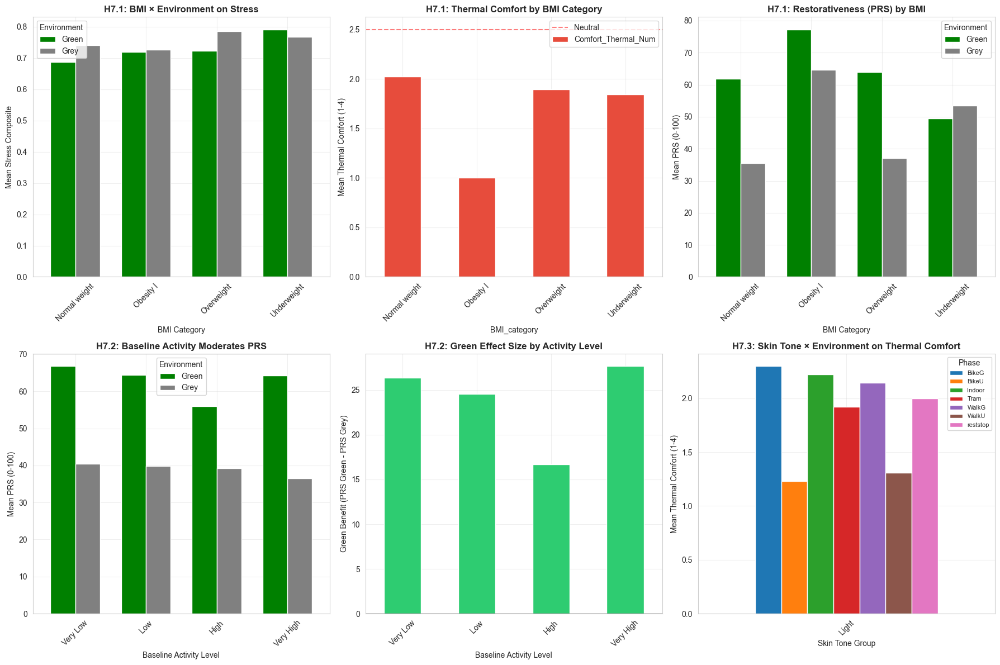

GROUP 7: INDIVIDUAL DIFFERENCES & EQUITY - STATISTICAL SUMMARY

H7.1 - BMI Moderation Effects:
Stress by BMI and Environment:
               Green   Grey
BMI_category               
Normal weight  0.688  0.741
Obesity I      0.719  0.727
Overweight     0.724  0.786
Underweight    0.792  0.767

Thermal Comfort by BMI:
                mean    std  count
BMI_category                      
Normal weight  2.023  1.000   1185
Obesity I      1.000  0.000    105
Overweight     1.896  0.996    393
Underweight    1.842  0.991    133

H7.2 - Activity Level Moderation:
PRS by Activity Level and Environment:
                 Green    Grey
Activity_Level                
Very Low        66.776  40.411
Low             64.365  39.843
High            55.905  39.242
Very High       64.227  36.568

Green Effect Size by Activity Level:
Activity_Level
Very Low     26.365
Low          24.522
High         16.662
Very High    27.660
dtype: float64

H7.3 - Skin Tone Effects:
Thermal Comfort by Skin Tone and Env

In [10]:
# GROUP 7: INDIVIDUAL DIFFERENCES & EQUITY
# Visualize H7.1, H7.2, H7.3

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# H7.1: BMI moderating green effect on stress reduction
ax1 = axes[0, 0]
bmi_stress_green = df[df['PhaseID'].isin(['WalkG', 'BikeG'])].groupby('BMI_category')[
    'eyetracker__stress_composite'].mean()
bmi_stress_grey = df[df['PhaseID'].isin(['WalkU', 'BikeU'])].groupby('BMI_category')[
    'eyetracker__stress_composite'].mean()

bmi_comparison = pd.DataFrame({
    'Green': bmi_stress_green,
    'Grey': bmi_stress_grey
})

bmi_comparison.plot(kind='bar', ax=ax1, color=['green', 'grey'], width=0.7)
ax1.set_title('H7.1: BMI × Environment on Stress', fontsize=12, fontweight='bold')
ax1.set_ylabel('Mean Stress Composite')
ax1.set_xlabel('BMI Category')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45)
ax1.legend(title='Environment')
ax1.grid(True, alpha=0.3)

# H7.1: Thermal Comfort by BMI
ax2 = axes[0, 1]
comfort_thermal_numeric_dict = {
    'Slightly non comfortable': 1,
    'Comfortable': 3,
    'Slightly comfortable': 2,
    'Very comfortable': 4
}
df['Comfort_Thermal_Num'] = df['Comfort-Thermal'].map(comfort_thermal_numeric_dict)

thermal_by_bmi = df.groupby('BMI_category')['Comfort_Thermal_Num'].mean()
colors_bmi = ['#2ecc71' if x > 2.5 else '#e74c3c' for x in thermal_by_bmi.values]
thermal_by_bmi.plot(kind='bar', ax=ax2, color=colors_bmi)
ax2.set_title('H7.1: Thermal Comfort by BMI Category', fontsize=12, fontweight='bold')
ax2.set_ylabel('Mean Thermal Comfort (1-4)')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45)
ax2.axhline(y=2.5, color='r', linestyle='--', alpha=0.5, label='Neutral')
ax2.legend()
ax2.grid(True, alpha=0.3)

# H7.1: PRS by BMI
ax3 = axes[0, 2]
prs_by_bmi_green = df[df['PhaseID'].isin(['WalkG', 'BikeG'])].groupby('BMI_category')['PRS_total_100'].mean()
prs_by_bmi_grey = df[df['PhaseID'].isin(['WalkU', 'BikeU'])].groupby('BMI_category')['PRS_total_100'].mean()

prs_bmi = pd.DataFrame({
    'Green': prs_by_bmi_green,
    'Grey': prs_by_bmi_grey
})

prs_bmi.plot(kind='bar', ax=ax3, color=['green', 'grey'], width=0.7)
ax3.set_title('H7.1: Restorativeness (PRS) by BMI', fontsize=12, fontweight='bold')
ax3.set_ylabel('Mean PRS (0-100)')
ax3.set_xlabel('BMI Category')
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=45)
ax3.legend(title='Environment')
ax3.grid(True, alpha=0.3)

# H7.2: Baseline Activity Level moderates green effect
ax4 = axes[1, 0]
# Categorize by activity level quartiles
df['Activity_Level'] = pd.qcut(df['empatica__step_counts'].fillna(0), q=4, labels=['Very Low', 'Low', 'High', 'Very High'], duplicates='drop')

activity_prs_green = df[df['PhaseID'].isin(['WalkG', 'BikeG'])].groupby('Activity_Level')['PRS_total_100'].mean()
activity_prs_grey = df[df['PhaseID'].isin(['WalkU', 'BikeU'])].groupby('Activity_Level')['PRS_total_100'].mean()

activity_prs = pd.DataFrame({
    'Green': activity_prs_green,
    'Grey': activity_prs_grey
})

activity_prs.plot(kind='bar', ax=ax4, color=['green', 'grey'], width=0.7)
ax4.set_title('H7.2: Baseline Activity Moderates PRS', fontsize=12, fontweight='bold')
ax4.set_ylabel('Mean PRS (0-100)')
ax4.set_xlabel('Baseline Activity Level')
ax4.set_xticklabels(ax4.get_xticklabels(), rotation=45)
ax4.legend(title='Environment')
ax4.grid(True, alpha=0.3)

# H7.2: Green Effect Size by Activity Level
ax5 = axes[1, 1]
green_effect_sizes = activity_prs['Green'] - activity_prs['Grey']
colors_effect = ['#2ecc71' if x > 0 else '#e74c3c' for x in green_effect_sizes.values]
green_effect_sizes.plot(kind='bar', ax=ax5, color=colors_effect)
ax5.set_title('H7.2: Green Effect Size by Activity Level', fontsize=12, fontweight='bold')
ax5.set_ylabel('Green Benefit (PRS Green - PRS Grey)')
ax5.set_xlabel('Baseline Activity Level')
ax5.set_xticklabels(ax5.get_xticklabels(), rotation=45)
ax5.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax5.grid(True, alpha=0.3)

# H7.3: Skin Tone effects on thermal comfort in different environments
ax6 = axes[1, 2]
# Group skin tone into Fair (light) and Dark (dark)
skin_tone_mapping = {
    '1 Very Fair': 'Light',
    '2 Fair': 'Light',
    '3 Light Brown': 'Medium',
    '4 Medium Brown': 'Medium',
    '5 Dark Brown': 'Dark',
    '6 Very Dark': 'Dark'
}
df['Skin_Tone_Group'] = df['Skin_Tone'].map(skin_tone_mapping)

thermal_by_skin_env = df.pivot_table(values='Comfort_Thermal_Num', 
                                      index='Skin_Tone_Group', 
                                      columns='PhaseID', 
                                      aggfunc='mean')

thermal_by_skin_env.plot(kind='bar', ax=ax6, width=0.8)
ax6.set_title('H7.3: Skin Tone × Environment on Thermal Comfort', fontsize=12, fontweight='bold')
ax6.set_ylabel('Mean Thermal Comfort (1-4)')
ax6.set_xlabel('Skin Tone Group')
ax6.set_xticklabels(ax6.get_xticklabels(), rotation=45)
ax6.legend(title='Phase', fontsize=8)
ax6.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(r'c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\Group7_Equity.png', dpi=300, bbox_inches='tight')
plt.show()

# Statistical Summary
print("=" * 80)
print("GROUP 7: INDIVIDUAL DIFFERENCES & EQUITY - STATISTICAL SUMMARY")
print("=" * 80)
print(f"\nH7.1 - BMI Moderation Effects:")
print("Stress by BMI and Environment:")
print(bmi_comparison.round(3))

print(f"\nThermal Comfort by BMI:")
print(df.groupby('BMI_category')['Comfort_Thermal_Num'].agg(['mean', 'std', 'count']).round(3))

print(f"\nH7.2 - Activity Level Moderation:")
print("PRS by Activity Level and Environment:")
print(activity_prs.round(3))
print("\nGreen Effect Size by Activity Level:")
print(green_effect_sizes.round(3))

print(f"\nH7.3 - Skin Tone Effects:")
print("Thermal Comfort by Skin Tone and Environment:")
print(thermal_by_skin_env.round(3))

---

### GROUP 8: ACTIVITY-ENVIRONMENT INTERACTIONS
**Nested under Main Hypothesis 4**

H8.1 The green-grey benefit flips by activity type: walking benefits more from green (preference-driven), while cycling shows equal comfort in both (aerodynamic/speed factors overcome green preference).
- **Variables**: `PhaseID`, `Pleasantness_100`, `Comfort_0_100`, `PRS_total_100`

H8.2 The tram passage is a critical transition point: thermal discomfort rebound after tram (larger UTCI jump) extends recovery time, especially post-green exposure (sensitization effect).
- **Variables**: `PhaseID`, `ExpTime`, `ucm__utci`, `Comfort-Thermal`, `ucm__air_temp`, `Indoor`

H8.3 Movement variability and gait speed normalize (become less variable) in green areas, suggesting reduced postural/motor vigilance, while grey areas show sustained elevated variability (defensive posture).
- **Variables**: `PhaseID`, `lys1__movement`, `lys2__movement`, `empatica__acticounts_x_axis`, `empatica__acticounts_y_axis`, `empatica__acticounts_z_axis`

In [18]:
# H8.3: Movement/Activity intensity by environment
ax6 = axes[1, 2]
# Convert Avg_lys_Movement to numeric (it's stored as object/string)
df['Avg_lys_Movement_numeric'] = pd.to_numeric(df['Avg_lys_Movement'], errors='coerce')
movement_by_phase = df.groupby('PhaseID')[['Avg_lys_Movement_numeric', 'empatica__activity_counts']].mean()

# Normalize to 0-100 scale for visualization
if len(movement_by_phase.dropna()) > 1:
    movement_norm = (movement_by_phase['Avg_lys_Movement_numeric'] - movement_by_phase['Avg_lys_Movement_numeric'].min()) / \
                    (movement_by_phase['Avg_lys_Movement_numeric'].max() - movement_by_phase['Avg_lys_Movement_numeric'].min() + 0.001) * 100
    activity_norm = (movement_by_phase['empatica__activity_counts'] - movement_by_phase['empatica__activity_counts'].min()) / \
                    (movement_by_phase['empatica__activity_counts'].max() - movement_by_phase['empatica__activity_counts'].min() + 0.001) * 100
    
    movement_activity = pd.DataFrame({
        'LYS Movement': movement_norm,
        'Empatica Activity': activity_norm
    })
    
    colors_mov = ['green' if 'G' in idx else 'grey' for idx in movement_activity.index]
    movement_activity.plot(kind='bar', ax=ax6, color=['#3498db', '#e74c3c'], width=0.8)
    ax6.set_title('H8.3: Movement & Activity Intensity by Phase', fontsize=12, fontweight='bold')
    ax6.set_ylabel('Normalized Intensity (0-100)')
    ax6.set_xticklabels(ax6.get_xticklabels(), rotation=45)
    ax6.legend(fontsize=8)
    ax6.grid(True, alpha=0.3)

PARTICIPANT-BY-PARTICIPANT THERMAL VULNERABILITY & PHYSIOLOGICAL RESPONSE PROFILES

Creating per-participant profiles for 18 participants
Layout: [ParticipantID] [BMI on global distribution] [1-6: ITVS, StressIdx, ECI, UTCI_Z, HR_Z, EDA_Z] [SkinTemp] [EDA]
Figure saved: c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\21_Per_Participant_Profiles.png


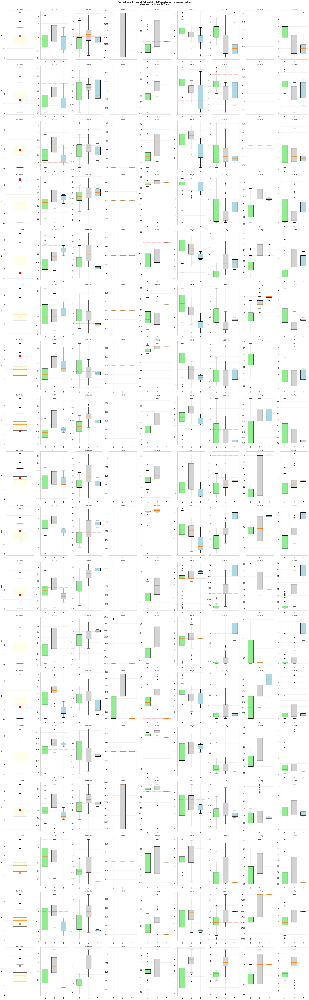


PER-PARTICIPANT MEAN VALUES ACROSS ALL PHASES

ParticipantID | BMI  | ITVS   | StressIdx | ECI  | UTCI_Z | HR_Z | EDA_Z | SkinTemp | EDA_raw
----------------------------------------------------------------------------------------------------
       1     |  0.26 | -0.077 |    -0.028 |  2.57 |   0.02 |  0.12 |  0.11 |    27.20 |     6.68
       2     | -0.62 | -0.310 |     0.112 |  2.50 |   0.06 |  1.19 | -0.18 |    27.20 |     4.13
       3     | -0.10 |  0.304 |    -0.074 |  2.73 |   0.10 |  0.47 | -0.33 |    27.20 |     2.81
       4     |  2.51 |  0.381 |    -0.379 |  2.50 |  -0.10 | -0.53 | -0.43 |    26.46 |     1.93
       5     | -1.45 | -0.279 |     0.156 |  2.50 |  -0.20 |  0.20 | -0.49 |    26.33 |     1.37
       6     | -0.32 |  0.004 |     0.336 |  2.50 |  -0.17 |  0.89 | -0.23 |    25.73 |     3.64
       7     |  1.41 |  0.053 |     0.136 |  2.50 |  -0.11 |  0.38 |  0.40 |    25.75 |     9.22
       8     | -0.68 | -0.330 |    -0.269 |  2.50 |  -0.07 | -0.28 | -0.33 |  

In [26]:
# CELL 21: PER-PARTICIPANT ANALYSIS SHOWING INDIVIDUAL PROFILES ACROSS ENVIRONMENTS
# Layout: For each participant in a row: [BMI position] [6 indices Green/Grey/Tram] [Skin Temp] [EDA]

import numpy as np
from scipy.stats import zscore

print("="*100)
print("PARTICIPANT-BY-PARTICIPANT THERMAL VULNERABILITY & PHYSIOLOGICAL RESPONSE PROFILES")
print("="*100)

# ============================================================================
# PREPARE DATA: Create indices for all rows
# ============================================================================

# Select and prepare working dataframe
work_cols = ['ParticipantID', 'PhaseID', 'ucm__utci', 'ucm__pet', 'empatica__met', 'clo_sum', 'BMI',
             'empatica__eda_scl_usiemens', 'empatica__pulse_rate_bpm', 'eyetracker__pupil_diameter_avg',
             'Comfort-Thermal', 'Comfort-Acoustic', 'Comfort-Visual']

work_df = df[work_cols].copy()

# Fill numeric NaNs with column means
for col in work_df.columns:
    if col not in ['ParticipantID', 'PhaseID', 'Comfort-Thermal', 'Comfort-Acoustic', 'Comfort-Visual']:
        work_df[col] = pd.to_numeric(work_df[col], errors='coerce').fillna(work_df[col].mean())

# Find sound column
sound_cols = [col for col in df.columns if 'snd' in col.lower()]
sound_col = sound_cols[0] if sound_cols else 'ucm__snd_dba'
work_df['Noise'] = df[sound_col].fillna(df[sound_col].mean())

# Find skin temperature column
skin_temp_cols = [col for col in df.columns if 'skin_temp' in col.lower() or 'temperature' in col.lower()]
skin_temp_col = skin_temp_cols[0] if skin_temp_cols else None
if skin_temp_col:
    work_df['SkinTemp'] = df[skin_temp_col].fillna(df[skin_temp_col].mean())
else:
    work_df['SkinTemp'] = df['empatica__met'].fillna(df['empatica__met'].mean())  # fallback

work_clean = work_df[['ParticipantID', 'PhaseID', 'ucm__utci', 'ucm__pet', 'empatica__met', 'clo_sum', 'BMI',
                      'empatica__eda_scl_usiemens', 'empatica__pulse_rate_bpm', 'eyetracker__pupil_diameter_avg',
                      'Comfort-Thermal', 'Comfort-Acoustic', 'Comfort-Visual', 'Noise', 'SkinTemp']].copy()

# ============================================================================
# CALCULATE INDICES (Z-scores)
# ============================================================================

indices_df = pd.DataFrame()
indices_df['ParticipantID'] = work_clean['ParticipantID']
indices_df['PhaseID'] = work_clean['PhaseID']

# ITVS (Thermal Vulnerability)
indices_df['UTCI_Z'] = zscore(work_clean['ucm__utci'])
indices_df['PET_Z'] = zscore(work_clean['ucm__pet'])
indices_df['MET_Z'] = zscore(work_clean['empatica__met'])
indices_df['Clo_Z'] = zscore(work_clean['clo_sum'])
indices_df['BMI_Z'] = zscore(work_clean['BMI'])
indices_df['ITVS'] = (indices_df['UTCI_Z'] + indices_df['PET_Z'] + 
                      indices_df['MET_Z'] + indices_df['Clo_Z'] + indices_df['BMI_Z']) / 5

# Stress Index
indices_df['EDA_Z'] = zscore(work_clean['empatica__eda_scl_usiemens'])
indices_df['HR_Z'] = zscore(work_clean['empatica__pulse_rate_bpm'])
indices_df['Pupil_Z'] = zscore(work_clean['eyetracker__pupil_diameter_avg'])
indices_df['Noise_Z'] = zscore(work_clean['Noise'])
indices_df['StressIndex'] = (indices_df['EDA_Z'] + indices_df['HR_Z'] + 
                             indices_df['Pupil_Z'] + indices_df['Noise_Z']) / 4

# Environmental Comfort Index
def map_comfort(val):
    if pd.isna(val):
        return 2.5
    val_lower = str(val).lower().strip()
    if 'very' in val_lower and 'comfortable' in val_lower:
        return 3.0
    elif 'comfortable' in val_lower:
        return 2.5
    elif 'slightly' in val_lower and 'non' in val_lower:
        return 1.5
    elif 'non' in val_lower:
        return 1.0
    else:
        return 2.5

indices_df['Comfort_Thermal_Num'] = work_clean['Comfort-Thermal'].apply(map_comfort)
indices_df['Comfort_Acoustic_Num'] = work_clean['Comfort-Acoustic'].apply(map_comfort)
indices_df['Comfort_Visual_Num'] = work_clean['Comfort-Visual'].apply(map_comfort)
indices_df['ECI'] = (indices_df['Comfort_Thermal_Num'] + indices_df['Comfort_Acoustic_Num'] + 
                     indices_df['Comfort_Visual_Num']) / 3

# Skin temperature and EDA (raw values)
indices_df['SkinTemp'] = work_clean['SkinTemp']
indices_df['EDA'] = work_clean['empatica__eda_scl_usiemens']

# Get unique participants
participants = sorted(indices_df['ParticipantID'].unique())
bmi_values = indices_df.groupby('ParticipantID')['BMI_Z'].mean()

print(f"\nCreating per-participant profiles for {len(participants)} participants")
print("Layout: [ParticipantID] [BMI on global distribution] [1-6: ITVS, StressIdx, ECI, UTCI_Z, HR_Z, EDA_Z] [SkinTemp] [EDA]")

# ============================================================================
# CREATE PER-PARTICIPANT FIGURE (9 columns x 18 rows)
# ============================================================================

fig, axes = plt.subplots(len(participants), 9, figsize=(28, 5*len(participants)))

# Create global BMI boxplot reference data
all_bmi_z = indices_df['BMI_Z'].values

# Color scheme for phases
phase_colors = {'WalkG': 'limegreen', 'BikeG': 'green', 'WalkU': 'darkgrey', 
                'BikeU': 'grey', 'Indoor': 'lightblue'}
phase_labels = {'WalkG': 'G', 'BikeG': 'G', 'WalkU': 'U', 'BikeU': 'U', 'Indoor': 'T'}

for row, pid in enumerate(participants):
    pid_data = indices_df[indices_df['ParticipantID'] == pid]
    
    # Extract phase data
    green_mask = pid_data['PhaseID'].isin(['WalkG', 'BikeG'])
    grey_mask = pid_data['PhaseID'].isin(['WalkU', 'BikeU'])
    tram_mask = pid_data['PhaseID'] == 'Indoor'
    
    # COL 1: BMI - Show global BMI distribution with cross for this participant
    ax = axes[row, 0] if len(participants) > 1 else axes[0]
    ax.boxplot([all_bmi_z], widths=0.5, patch_artist=True, 
               boxprops=dict(facecolor='lightyellow', alpha=0.7))
    ax.scatter([1], [bmi_values[pid]], marker='x', s=200, color='red', linewidths=3, zorder=5)
    ax.set_ylabel(f'P{int(pid)}', fontsize=10, fontweight='bold')
    ax.set_xticks([])
    ax.set_title('BMI Position', fontsize=9)
    ax.grid(True, alpha=0.3)
    
    # COL 2: ITVS
    ax = axes[row, 1] if len(participants) > 1 else axes[1]
    itvs_data = [pid_data[green_mask]['ITVS'].dropna().values,
                 pid_data[grey_mask]['ITVS'].dropna().values,
                 pid_data[tram_mask]['ITVS'].dropna().values]
    bp = ax.boxplot(itvs_data, labels=['G', 'U', 'T'], widths=0.6, patch_artist=True)
    for patch, color in zip(bp['boxes'], ['lightgreen', 'lightgrey', 'lightblue']):
        patch.set_facecolor(color)
    ax.axhline(y=0, color='red', linestyle='--', alpha=0.2)
    ax.set_title('1. ITVS', fontsize=9)
    ax.grid(True, alpha=0.3)
    
    # COL 3: Stress Index
    ax = axes[row, 2] if len(participants) > 1 else axes[2]
    stress_data = [pid_data[green_mask]['StressIndex'].dropna().values,
                   pid_data[grey_mask]['StressIndex'].dropna().values,
                   pid_data[tram_mask]['StressIndex'].dropna().values]
    bp = ax.boxplot(stress_data, labels=['G', 'U', 'T'], widths=0.6, patch_artist=True)
    for patch, color in zip(bp['boxes'], ['lightgreen', 'lightgrey', 'lightblue']):
        patch.set_facecolor(color)
    ax.axhline(y=0, color='red', linestyle='--', alpha=0.2)
    ax.set_title('2. StressIdx', fontsize=9)
    ax.grid(True, alpha=0.3)
    
    # COL 4: ECI
    ax = axes[row, 3] if len(participants) > 1 else axes[3]
    eci_data = [pid_data[green_mask]['ECI'].dropna().values,
                pid_data[grey_mask]['ECI'].dropna().values,
                pid_data[tram_mask]['ECI'].dropna().values]
    bp = ax.boxplot(eci_data, labels=['G', 'U', 'T'], widths=0.6, patch_artist=True)
    for patch, color in zip(bp['boxes'], ['lightgreen', 'lightgrey', 'lightblue']):
        patch.set_facecolor(color)
    ax.set_title('3. ECI', fontsize=9)
    ax.grid(True, alpha=0.3)
    
    # COL 5: UTCI Z-score
    ax = axes[row, 4] if len(participants) > 1 else axes[4]
    utci_data = [pid_data[green_mask]['UTCI_Z'].dropna().values,
                 pid_data[grey_mask]['UTCI_Z'].dropna().values,
                 pid_data[tram_mask]['UTCI_Z'].dropna().values]
    bp = ax.boxplot(utci_data, labels=['G', 'U', 'T'], widths=0.6, patch_artist=True)
    for patch, color in zip(bp['boxes'], ['lightgreen', 'lightgrey', 'lightblue']):
        patch.set_facecolor(color)
    ax.axhline(y=0, color='red', linestyle='--', alpha=0.2)
    ax.set_title('4. UTCI_Z', fontsize=9)
    ax.grid(True, alpha=0.3)
    
    # COL 6: Heart Rate Z-score
    ax = axes[row, 5] if len(participants) > 1 else axes[5]
    hr_data = [pid_data[green_mask]['HR_Z'].dropna().values,
               pid_data[grey_mask]['HR_Z'].dropna().values,
               pid_data[tram_mask]['HR_Z'].dropna().values]
    bp = ax.boxplot(hr_data, labels=['G', 'U', 'T'], widths=0.6, patch_artist=True)
    for patch, color in zip(bp['boxes'], ['lightgreen', 'lightgrey', 'lightblue']):
        patch.set_facecolor(color)
    ax.axhline(y=0, color='red', linestyle='--', alpha=0.2)
    ax.set_title('5. HR_Z', fontsize=9)
    ax.grid(True, alpha=0.3)
    
    # COL 7: EDA Z-score
    ax = axes[row, 6] if len(participants) > 1 else axes[6]
    eda_z_data = [pid_data[green_mask]['EDA_Z'].dropna().values,
                  pid_data[grey_mask]['EDA_Z'].dropna().values,
                  pid_data[tram_mask]['EDA_Z'].dropna().values]
    bp = ax.boxplot(eda_z_data, labels=['G', 'U', 'T'], widths=0.6, patch_artist=True)
    for patch, color in zip(bp['boxes'], ['lightgreen', 'lightgrey', 'lightblue']):
        patch.set_facecolor(color)
    ax.axhline(y=0, color='red', linestyle='--', alpha=0.2)
    ax.set_title('6. EDA_Z', fontsize=9)
    ax.grid(True, alpha=0.3)
    
    # COL 8: Skin Temperature
    ax = axes[row, 7] if len(participants) > 1 else axes[7]
    skintemp_data = [pid_data[green_mask]['SkinTemp'].dropna().values,
                     pid_data[grey_mask]['SkinTemp'].dropna().values,
                     pid_data[tram_mask]['SkinTemp'].dropna().values]
    bp = ax.boxplot(skintemp_data, labels=['G', 'U', 'T'], widths=0.6, patch_artist=True)
    for patch, color in zip(bp['boxes'], ['lightgreen', 'lightgrey', 'lightblue']):
        patch.set_facecolor(color)
    ax.set_title('Skin Temp', fontsize=9)
    ax.grid(True, alpha=0.3)
    
    # COL 9: EDA (raw)
    ax = axes[row, 8] if len(participants) > 1 else axes[8]
    eda_raw_data = [pid_data[green_mask]['EDA'].dropna().values,
                    pid_data[grey_mask]['EDA'].dropna().values,
                    pid_data[tram_mask]['EDA'].dropna().values]
    bp = ax.boxplot(eda_raw_data, labels=['G', 'U', 'T'], widths=0.6, patch_artist=True)
    for patch, color in zip(bp['boxes'], ['lightgreen', 'lightgrey', 'lightblue']):
        patch.set_facecolor(color)
    ax.set_title('EDA (Raw)', fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Per-Participant Thermal Vulnerability & Physiological Response Profiles\n[G=Green, U=Urban, T=Tram]', 
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(r'c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\21_Per_Participant_Profiles.png', 
            dpi=300, bbox_inches='tight')
print(r"Figure saved: c:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\Figures\21_Per_Participant_Profiles.png")
plt.show()

# ============================================================================
# SUMMARY TABLE: Per-Participant Mean Values
# ============================================================================
print("\n" + "="*100)
print("PER-PARTICIPANT MEAN VALUES ACROSS ALL PHASES")
print("="*100)
print("\nParticipantID | BMI  | ITVS   | StressIdx | ECI  | UTCI_Z | HR_Z | EDA_Z | SkinTemp | EDA_raw")
print("-" * 100)

for pid in participants:
    pid_data = indices_df[indices_df['ParticipantID'] == pid]
    print(f"      {int(pid):2.0f}     | {pid_data['BMI_Z'].mean():5.2f} | {pid_data['ITVS'].mean():6.3f} | " + 
          f"{pid_data['StressIndex'].mean():9.3f} | {pid_data['ECI'].mean():5.2f} | {pid_data['UTCI_Z'].mean():6.2f} | " +
          f"{pid_data['HR_Z'].mean():5.2f} | {pid_data['EDA_Z'].mean():5.2f} | {pid_data['SkinTemp'].mean():8.2f} | {pid_data['EDA'].mean():8.2f}")

print("="*100)

## Dashboard

Participants: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
Loading raw GPS data ...
Done. Generating 5 phase figures ...


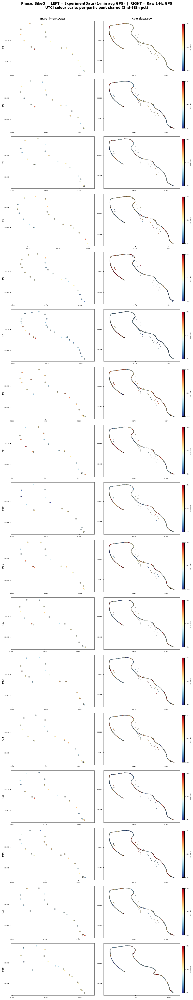

  Phase BikeG done.


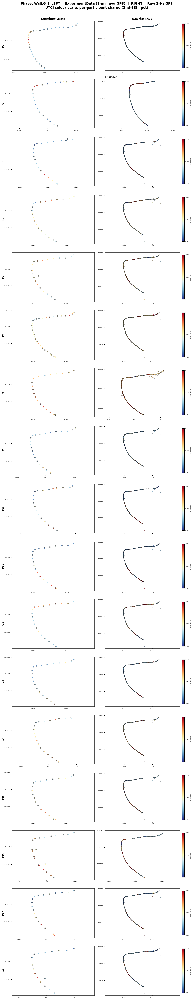

  Phase WalkG done.


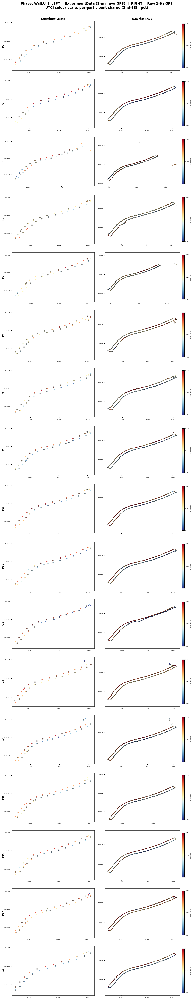

  Phase WalkU done.


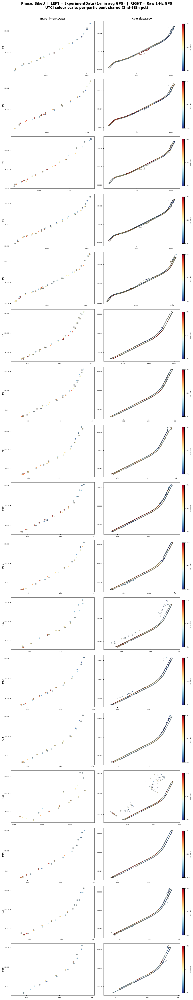

  Phase BikeU done.


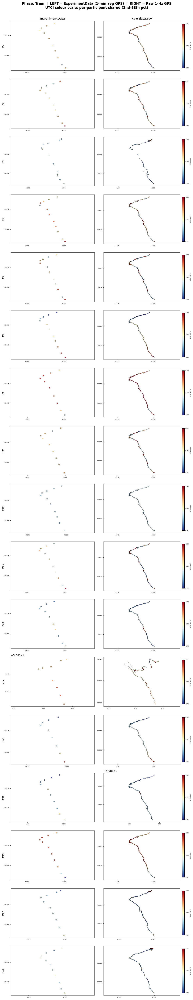

  Phase Tram done.
All phases complete.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from io import StringIO
import os
import warnings
warnings.filterwarnings('ignore')

RAW_BASE = r"C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Complete Participantwise data"
EXP_CSV  = r"C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Experiment material\ExperimentData_18Mar.csv"
PHASES   = ['BikeG', 'WalkG', 'WalkU', 'BikeU', 'Tram']
UTCI_MIN, UTCI_MAX = -40, 60
CMAP = 'RdYlBu_r'

# ── Helper: find data.csv anywhere inside the ucm folder (handles subfolders) ─
def find_ucm_csv(pid, phase):
    ucm_dir = os.path.join(RAW_BASE, f'P{pid}', phase, 'ucm')
    if not os.path.isdir(ucm_dir):
        return None
    direct = os.path.join(ucm_dir, 'data.csv')
    if os.path.exists(direct):
        return direct
    for root, _, files in os.walk(ucm_dir):
        if 'data.csv' in files:
            return os.path.join(root, 'data.csv')
    return None

# ── Load ExperimentData ───────────────────────────────────────────────────────
exp_all = pd.read_csv(EXP_CSV, encoding='latin-1')
for c in ['ucm__gps_lat', 'ucm__gps_lon', 'ucm__utci']:
    exp_all[c] = pd.to_numeric(exp_all[c], errors='coerce')
participants = sorted([int(p) for p in exp_all['ParticipantID'].dropna().unique()])
print(f"Participants: {participants}")

# ── Load raw GPS+UTCI per participant per phase ───────────────────────────────
print("Loading raw GPS data ...", flush=True)
raw_all = {}
for pid in participants:
    raw_all[pid] = {}
    for phase in PHASES:
        path = find_ucm_csv(pid, phase)
        if path is None:
            continue
        with open(path, 'r', encoding='latin-1') as fh:
            lines = fh.readlines()
        hdr = next((l for l in lines if l.startswith('# GPS_time')), None)
        if hdr is None:
            continue
        cols = hdr.strip().lstrip('# ').split(',')
        df = pd.read_csv(StringIO(''.join([l for l in lines if not l.startswith('#')])), names=cols)
        for c in ['GPS_lat', 'GPS_lon', 'UTCI']:
            df[c] = pd.to_numeric(df[c], errors='coerce')
        df = df.dropna(subset=['GPS_lat', 'GPS_lon', 'UTCI'])
        df = df[(df['UTCI'] >= UTCI_MIN) & (df['UTCI'] <= UTCI_MAX)]
        df = df[(df['GPS_lat'].abs() > 0.001) & (df['GPS_lon'].abs() > 0.001)]
        if len(df):
            raw_all[pid][phase] = df[['GPS_lat', 'GPS_lon', 'UTCI']].reset_index(drop=True)

print("Done. Generating 5 phase figures ...")

# ── One figure per phase ──────────────────────────────────────────────────────
for phase in PHASES:
    n_rows = len(participants)
    fig, axes = plt.subplots(n_rows, 2, figsize=(10, 3.0 * n_rows), squeeze=False)
    fig.suptitle(
        f'Phase: {phase}  |  LEFT = ExperimentData (1-min avg GPS)  |  RIGHT = Raw 1-Hz GPS\n'
        f'UTCI colour scale: per-participant shared (2nd-98th pct)',
        fontsize=12, fontweight='bold', y=1.002
    )
    axes[0, 0].set_title('ExperimentData', fontsize=10, fontweight='bold')
    axes[0, 1].set_title('Raw data.csv', fontsize=10, fontweight='bold')

    for row_idx, pid in enumerate(participants):
        ax_l = axes[row_idx, 0]
        ax_r = axes[row_idx, 1]

        # Gather ExpData for this participant + phase
        exp_p = exp_all[
            (exp_all['ParticipantID'] == pid) & (exp_all['PhaseID'] == phase)
        ][['ucm__gps_lat', 'ucm__gps_lon', 'ucm__utci']].dropna()

        # Gather raw for this participant + phase
        raw_p = raw_all[pid].get(phase, pd.DataFrame())

        # Shared UTCI colour range from both sources
        vals = np.concatenate([
            exp_p['ucm__utci'].values if len(exp_p) else np.array([]),
            raw_p['UTCI'].values if len(raw_p) else np.array([])
        ])
        if len(vals) >= 4:
            vmin = float(np.percentile(vals, 2))
            vmax = float(np.percentile(vals, 98))
        elif len(vals):
            vmin, vmax = float(vals.min()), float(vals.max())
        else:
            vmin, vmax = 15.0, 35.0
        if vmax - vmin < 0.5:
            vmin -= 0.25; vmax += 0.25
        norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

        # ── LEFT: ExperimentData ──────────────────────────────────────────────
        ax_l.set_facecolor('white')
        if len(exp_p):
            sc = ax_l.scatter(
                exp_p['ucm__gps_lon'], exp_p['ucm__gps_lat'],
                c=exp_p['ucm__utci'], cmap=CMAP, norm=norm,
                s=18, linewidths=0.4, edgecolors='black', alpha=0.9, zorder=2
            )
            ax_l.set_aspect('equal', adjustable='datalim')
        else:
            ax_l.text(0.5, 0.5, 'No data', ha='center', va='center',
                      fontsize=8, color='#888', transform=ax_l.transAxes)
        ax_l.set_ylabel(f'P{pid}', fontsize=8, fontweight='bold', labelpad=2)
        ax_l.tick_params(labelsize=5, length=2)
        ax_l.xaxis.set_major_locator(plt.MaxNLocator(3))
        ax_l.yaxis.set_major_locator(plt.MaxNLocator(3))
        for spine in ax_l.spines.values():
            spine.set_linewidth(0.5)

        # ── RIGHT: Raw data ───────────────────────────────────────────────────
        ax_r.set_facecolor('white')
        if len(raw_p):
            sc2 = ax_r.scatter(
                raw_p['GPS_lon'], raw_p['GPS_lat'],
                c=raw_p['UTCI'], cmap=CMAP, norm=norm,
                s=3, linewidths=0.3, edgecolors='black', alpha=0.7, zorder=2, rasterized=True
            )
            ax_r.set_aspect('equal', adjustable='datalim')
        else:
            ax_r.text(0.5, 0.5, 'No data', ha='center', va='center',
                      fontsize=8, color='#888', transform=ax_r.transAxes)
        ax_r.tick_params(labelsize=5, length=2)
        ax_r.xaxis.set_major_locator(plt.MaxNLocator(3))
        ax_r.yaxis.set_major_locator(plt.MaxNLocator(3))
        for spine in ax_r.spines.values():
            spine.set_linewidth(0.5)

        # Colorbar on right edge
        sm = cm.ScalarMappable(cmap=CMAP, norm=norm)
        sm.set_array([])
        cb = fig.colorbar(sm, ax=ax_r, fraction=0.06, pad=0.03, shrink=0.9)
        cb.set_label('UTCI deg C', fontsize=5, labelpad=2)
        cb.ax.tick_params(labelsize=5)
        cb.set_ticks([vmin, (vmin + vmax) / 2, vmax])
        cb.set_ticklabels([f'{vmin:.1f}', f'{(vmin+vmax)/2:.1f}', f'{vmax:.1f}'])

    plt.tight_layout()
    plt.show()
    print(f"  Phase {phase} done.")

print("All phases complete.")


Parsing KML ...
  BikeG: 92 segments
  WalkG: 92 segments
  WalkU: 172 segments
  BikeU: 172 segments
  Tram: 100 segments
Loading raw GPS ...
Done.
Computing spatial UTCI offsets ...
  BikeG: segs=92  exp=82  raw=82
  WalkG: segs=92  exp=48  raw=51
  WalkU: segs=172  exp=171  raw=171
  BikeU: segs=172  exp=168  raw=171
  Tram: segs=100  exp=55  raw=58
UTCI offset colour range: -8.89 to 0.00 degC


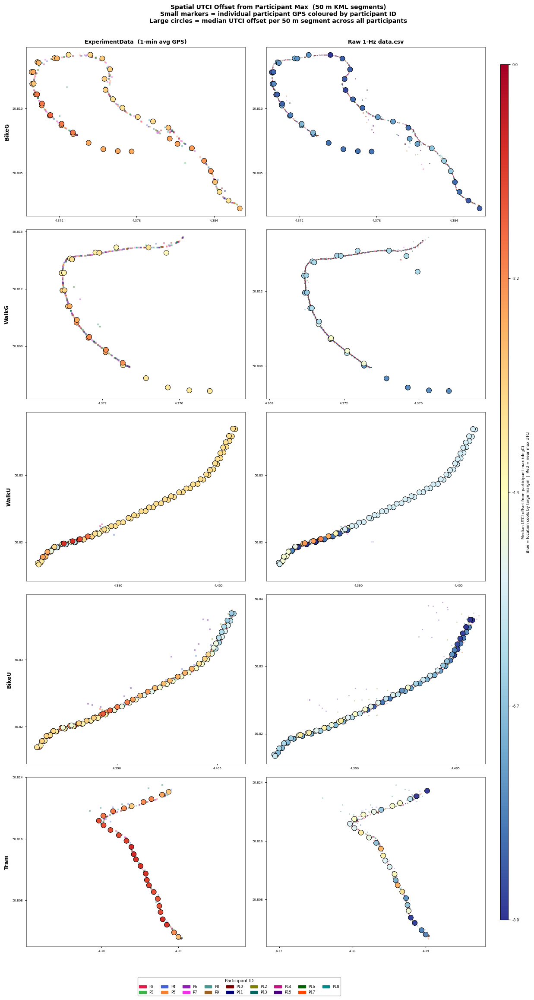

Enriched spatial UTCI offset plot complete.


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from io import StringIO
import os, xml.etree.ElementTree as ET
from scipy.spatial import cKDTree
import warnings
warnings.filterwarnings('ignore')

RAW_BASE = r"C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Complete Participantwise data"
EXP_CSV  = r"C:\Users\pandya\OneDrive - UCL\Field experiment raw data\Experiment material\ExperimentData_18Mar.csv"
KML_PATH = r"C:\Users\pandya\OneDrive - UCL\Pranav PhD\Paper 3\QGIS\split lines by maximum length 50m.kml"
PHASES   = ['BikeG', 'WalkG', 'WalkU', 'BikeU', 'Tram']
UTCI_MIN, UTCI_MAX = -40, 60
KML_NS = 'http://www.opengis.net/kml/2.2'

# KML uses route names; map to experiment phases
KML_ROUTE_TO_PHASES = {
    'Green': ['BikeG', 'WalkG'],
    'Urban': ['WalkU', 'BikeU'],
    'Tram':  ['Tram'],
}

# 17 distinct vivid participant colours (no pale/yellow/light tones)
PART_COLORS = [
    '#e6194b', '#3cb44b', '#4363d8', '#f58231', '#911eb4',
    '#f032e6', '#469990', '#9a6324', '#800000', '#000075',
    '#808000', '#00635d', '#C71585', '#4B0082', '#006400',
    '#FF4500', '#008B8B']

# ── Helpers ───────────────────────────────────────────────────────────────────
def find_ucm_csv(pid, phase):
    ucm_dir = os.path.join(RAW_BASE, f'P{pid}', phase, 'ucm')
    if not os.path.isdir(ucm_dir):
        return None
    direct = os.path.join(ucm_dir, 'data.csv')
    if os.path.exists(direct):
        return direct
    for rd, _, files in os.walk(ucm_dir):
        if 'data.csv' in files:
            return os.path.join(rd, 'data.csv')
    return None

def parse_kml_by_phase(kml_path):
    """
    Parses KML with route names (Green/Urban/Tram) and returns segments
    keyed by experiment phase using KML_ROUTE_TO_PHASES mapping.
    Returns {phase: [{'fid': int, 'lon': float, 'lat': float}, ...]} sorted by fid.
    """
    tree = ET.parse(kml_path)
    root = tree.getroot()
    route_segs = {}
    for pm in root.iter(f'{{{KML_NS}}}Placemark'):
        route, fid = None, None
        for sd in pm.iter(f'{{{KML_NS}}}SimpleData'):
            nm = sd.get('name', '')
            if nm == 'Phase' and sd.text:
                route = sd.text.strip()
            elif nm == 'fid' and sd.text:
                try:
                    fid = int(float(sd.text))
                except Exception:
                    pass
        if route is None or fid is None:
            continue
        lons, lats = [], []
        for poly in pm.iter(f'{{{KML_NS}}}Polygon'):
            lr = poly.find(f'.//{{{KML_NS}}}LinearRing/{{{KML_NS}}}coordinates')
            if lr is not None and lr.text:
                for tok in lr.text.strip().split():
                    parts = tok.split(',')
                    if len(parts) >= 2:
                        lons.append(float(parts[0]))
                        lats.append(float(parts[1]))
            break
        if lons:
            route_segs.setdefault(route, []).append(
                {'fid': fid, 'lon': float(np.mean(lons)), 'lat': float(np.mean(lats))})
    # Sort by fid within each route
    for segs in route_segs.values():
        segs.sort(key=lambda x: x['fid'])
    # Reindex fid within each route to 0-based (for gap-fill consistency)
    for segs in route_segs.values():
        for i, s in enumerate(segs):
            s['idx'] = i
    # Map to experiment phases
    pdict = {ph: [] for ph in PHASES}
    for route, exp_phases in KML_ROUTE_TO_PHASES.items():
        segs = route_segs.get(route, [])
        for ph in exp_phases:
            pdict[ph] = segs  # shared segments for same route
    return pdict

def assign_gap_fill(lat_arr, lon_arr, off_arr, kd, lat_s, lon_s, n_segs, thresh=80):
    """
    Assign GPS points to nearest 50m KML segment (within thresh metres).
    Gap-fill: between consecutive segments i -> j, fill i+1..j-1 with j's value
    (forward-fill from the NEXT observed point, as per user specification).
    Returns dict: seg_idx -> median utci_offset.
    """
    pts_m = np.column_stack([lat_arr, lon_arr]) * np.array([lat_s, lon_s])
    dists, idxs = kd.query(pts_m)
    valid = dists < thresh
    seg_raw = {}
    for i in range(len(lat_arr)):
        if valid[i]:
            si = int(idxs[i])
            seg_raw.setdefault(si, []).append(float(off_arr[i]))
    seg_med = {si: float(np.median(v)) for si, v in seg_raw.items()}
    sorted_si = sorted(seg_med.keys())
    filled = dict(seg_med)
    for k in range(len(sorted_si) - 1):
        a, b = sorted_si[k], sorted_si[k + 1]
        if b - a > 1:
            vb = seg_med[b]
            for fi in range(a + 1, b):
                if fi not in filled:
                    filled[fi] = vb
    return filled

# ── Load ExperimentData ───────────────────────────────────────────────────────
exp_all = pd.read_csv(EXP_CSV, encoding='latin-1')
for col in ['ucm__gps_lat', 'ucm__gps_lon', 'ucm__utci']:
    exp_all[col] = pd.to_numeric(exp_all[col], errors='coerce')
participants = sorted([int(p) for p in exp_all['ParticipantID'].dropna().unique()])
color_map = {pid: PART_COLORS[i % len(PART_COLORS)] for i, pid in enumerate(participants)}

# ── Parse KML ─────────────────────────────────────────────────────────────────
print("Parsing KML ...")
phase_segs = parse_kml_by_phase(KML_PATH)
for ph, segs in phase_segs.items():
    print(f"  {ph}: {len(segs)} segments")

# ── Load raw GPS+UTCI ─────────────────────────────────────────────────────────
print("Loading raw GPS ...")
raw_all = {}
for pid in participants:
    raw_all[pid] = {}
    for phase in PHASES:
        path = find_ucm_csv(pid, phase)
        if path is None:
            continue
        with open(path, 'r', encoding='latin-1') as fh:
            lines = fh.readlines()
        hdr = next((l for l in lines if l.startswith('# GPS_time')), None)
        if hdr is None:
            continue
        cols_raw = hdr.strip().lstrip('# ').split(',')
        df = pd.read_csv(
            StringIO(''.join(l for l in lines if not l.startswith('#'))),
            names=cols_raw)
        for col in ['GPS_lat', 'GPS_lon', 'UTCI']:
            df[col] = pd.to_numeric(df[col], errors='coerce')
        df = df.dropna(subset=['GPS_lat', 'GPS_lon', 'UTCI'])
        df = df[(df['UTCI'] >= UTCI_MIN) & (df['UTCI'] <= UTCI_MAX)]
        df = df[(df['GPS_lat'].abs() > 0.001) & (df['GPS_lon'].abs() > 0.001)]
        if len(df):
            raw_all[pid][phase] = df[['GPS_lat', 'GPS_lon', 'UTCI']].reset_index(drop=True)
print("Done.")

# ── Spatial aggregation per phase ─────────────────────────────────────────────
print("Computing spatial UTCI offsets ...")
phase_results = {}
for phase in PHASES:
    segs = phase_segs[phase]
    if not segs:
        phase_results[phase] = None
        continue
    n_segs = len(segs)
    seg_arr = np.array([[s['lat'], s['lon']] for s in segs])
    mid_lat  = float(np.mean(seg_arr[:, 0]))
    lat_s = 111000.0
    lon_s = 111000.0 * np.cos(np.radians(mid_lat))
    kd = cKDTree(seg_arr * np.array([lat_s, lon_s]))

    exp_agg = {i: [] for i in range(n_segs)}
    raw_agg = {i: [] for i in range(n_segs)}
    exp_pts = {pid: {'lons': [], 'lats': []} for pid in participants}
    raw_pts = {pid: {'lons': [], 'lats': []} for pid in participants}

    edf = exp_all[exp_all['PhaseID'] == phase]
    for pid in participants:
        # ExperimentData
        ep = edf[edf['ParticipantID'] == pid][
            ['ucm__gps_lat', 'ucm__gps_lon', 'ucm__utci']].dropna()
        if len(ep) >= 2:
            mu = float(ep['ucm__utci'].max())
            offs = (ep['ucm__utci'] - mu).values
            exp_pts[pid]['lons'].extend(ep['ucm__gps_lon'].tolist())
            exp_pts[pid]['lats'].extend(ep['ucm__gps_lat'].tolist())
            for si, v in assign_gap_fill(
                    ep['ucm__gps_lat'].values, ep['ucm__gps_lon'].values,
                    offs, kd, lat_s, lon_s, n_segs).items():
                if 0 <= si < n_segs:
                    exp_agg[si].append(v)
        # Raw
        rp = raw_all[pid].get(phase, pd.DataFrame())
        if len(rp) >= 2:
            mu = float(rp['UTCI'].max())
            offs = (rp['UTCI'] - mu).values
            sub = rp.iloc[::15]
            raw_pts[pid]['lons'].extend(sub['GPS_lon'].tolist())
            raw_pts[pid]['lats'].extend(sub['GPS_lat'].tolist())
            for si, v in assign_gap_fill(
                    rp['GPS_lat'].values, rp['GPS_lon'].values,
                    offs, kd, lat_s, lon_s, n_segs).items():
                if 0 <= si < n_segs:
                    raw_agg[si].append(v)

    exp_seg = np.array([np.median(exp_agg[i]) if exp_agg[i] else np.nan
                        for i in range(n_segs)])
    raw_seg = np.array([np.median(raw_agg[i]) if raw_agg[i] else np.nan
                        for i in range(n_segs)])
    print(f"  {phase}: segs={n_segs}  exp={int(np.sum(~np.isnan(exp_seg)))}  raw={int(np.sum(~np.isnan(raw_seg)))}")
    phase_results[phase] = {
        'segs': segs, 'exp_pts': exp_pts, 'raw_pts': raw_pts,
        'exp_seg': exp_seg, 'raw_seg': raw_seg}

# ── Global UTCI offset colour range ──────────────────────────────────────────
all_vals_off = np.concatenate([
    np.concatenate([r['exp_seg'][~np.isnan(r['exp_seg'])],
                    r['raw_seg'][~np.isnan(r['raw_seg'])]])
    for r in phase_results.values() if r is not None
])
off_vmin = float(np.percentile(all_vals_off, 2)) if len(all_vals_off) else -20.0
off_vmax = 0.0
off_norm = mcolors.Normalize(vmin=off_vmin, vmax=off_vmax)
OFF_CMAP = 'RdYlBu_r'
print(f"UTCI offset colour range: {off_vmin:.2f} to {off_vmax:.2f} degC")

# ── Figure: 5 rows x 2 cols ───────────────────────────────────────────────────
fig, axes = plt.subplots(len(PHASES), 2,
                         figsize=(13, 4.5 * len(PHASES)),
                         squeeze=False)
fig.suptitle(
    'Spatial UTCI Offset from Participant Max  (50 m KML segments)\n'
    'Small markers = individual participant GPS coloured by participant ID\n'
    'Large circles = median UTCI offset per 50 m segment across all participants',
    fontsize=10, fontweight='bold', y=1.002)
axes[0, 0].set_title('ExperimentData  (1-min avg GPS)', fontsize=9, fontweight='bold')
axes[0, 1].set_title('Raw 1-Hz data.csv', fontsize=9, fontweight='bold')

for ridx, phase in enumerate(PHASES):
    ax_l = axes[ridx, 0]
    ax_r = axes[ridx, 1]
    ax_l.set_ylabel(phase, fontsize=9, fontweight='bold', labelpad=4)
    r = phase_results.get(phase)
    if r is None:
        for ax in (ax_l, ax_r):
            ax.text(0.5, 0.5, 'No KML segments for this phase',
                    ha='center', va='center',
                    transform=ax.transAxes, fontsize=8, color='#888')
        continue

    segs   = r['segs']
    slons  = np.array([s['lon'] for s in segs])
    slats  = np.array([s['lat'] for s in segs])

    for ax, src in [(ax_l, 'exp'), (ax_r, 'raw')]:
        pts_dict = r['exp_pts'] if src == 'exp' else r['raw_pts']
        seg_agg  = r['exp_seg']  if src == 'exp' else r['raw_seg']
        dot_s    = 10 if src == 'exp' else 4
        mk       = 's' if src == 'exp' else 'o'

        ax.set_facecolor('white')

        # Background: individual participant GPS dots (coloured by participant)
        for pid in participants:
            p = pts_dict[pid]
            if p['lons']:
                ax.scatter(p['lons'], p['lats'],
                           color=color_map[pid],
                           s=dot_s, alpha=0.35, linewidths=0,
                           zorder=2, marker=mk)

        # Foreground: 50m segment aggregated UTCI-offset markers
        valid = ~np.isnan(seg_agg)
        if valid.any():
            sc = ax.scatter(slons[valid], slats[valid],
                            c=seg_agg[valid], cmap=OFF_CMAP, norm=off_norm,
                            s=70, linewidths=0.6, edgecolors='black',
                            alpha=0.95, zorder=4)

        ax.set_aspect('equal', adjustable='datalim')
        ax.tick_params(labelsize=5, length=2)
        ax.xaxis.set_major_locator(plt.MaxNLocator(3))
        ax.yaxis.set_major_locator(plt.MaxNLocator(3))
        for sp in ax.spines.values():
            sp.set_linewidth(0.4)

# Shared UTCI-offset colorbar on far right
fig.subplots_adjust(right=0.87)
cax = fig.add_axes([0.895, 0.06, 0.014, 0.88])
sm  = plt.cm.ScalarMappable(cmap=OFF_CMAP, norm=off_norm)
sm.set_array([])
cb_shared = fig.colorbar(sm, cax=cax)
cb_shared.set_label(
    'Median UTCI offset from participant max (degC)\n'
    'Blue = location cools by large margin  |  Red = near max UTCI',
    fontsize=6.5, labelpad=4)
cb_shared.ax.tick_params(labelsize=6)
tks = np.linspace(off_vmin, 0.0, 5)
cb_shared.set_ticks(tks)
cb_shared.set_ticklabels([f'{t:.1f}' for t in tks])

# Participant colour legend at bottom
leg_handles = [mpatches.Patch(color=color_map[pid], label=f'P{pid}')
               for pid in participants]
fig.legend(handles=leg_handles, title='Participant ID',
           fontsize=6, title_fontsize=7,
           loc='lower center', ncol=9,
           bbox_to_anchor=(0.43, -0.02),
           frameon=True, edgecolor='#aaa')

plt.tight_layout(rect=[0, 0.02, 0.88, 1.0])
plt.show()
print("Enriched spatial UTCI offset plot complete.")


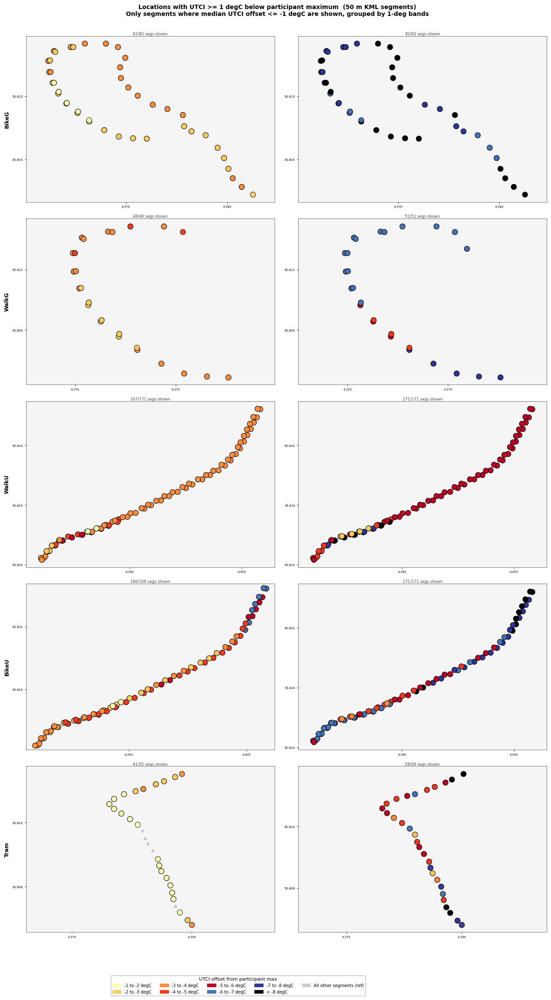

Done.


In [15]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── UTCI offset groups (1-deg bins, offset <= -1 degC) ────────────────────────
GROUPS = [
    (-1, -2,  '#ffffb2', '-1 to -2 degC'),
    (-2, -3,  '#fecc5c', '-2 to -3 degC'),
    (-3, -4,  '#fd8d3c', '-3 to -4 degC'),
    (-4, -5,  '#f03b20', '-4 to -5 degC'),
    (-5, -6,  '#bd0026', '-5 to -6 degC'),
    (-6, -7,  '#4575b4', '-6 to -7 degC'),
    (-7, -8,  '#313695', '-7 to -8 degC'),
    (-8, -999,'#000000', '< -8 degC'),
]

def get_group_color(val):
    for lo, hi, color, _ in GROUPS:
        if val <= lo and val > hi:
            return color
    return None  # above -1: excluded

# ── Figure: 5 rows x 2 cols ───────────────────────────────────────────────────
fig, axes = plt.subplots(len(PHASES), 2,
                         figsize=(13, 4.5 * len(PHASES)),
                         squeeze=False)
fig.suptitle(
    'Locations with UTCI >= 1 degC below participant maximum  (50 m KML segments)\n'
    'Only segments where median UTCI offset <= -1 degC are shown, grouped by 1-deg bands',
    fontsize=10, fontweight='bold', y=1.002)
axes[0, 0].set_title('ExperimentData  (1-min avg GPS)', fontsize=9, fontweight='bold')
axes[0, 1].set_title('Raw 1-Hz data.csv', fontsize=9, fontweight='bold')

for ridx, phase in enumerate(PHASES):
    ax_l = axes[ridx, 0]
    ax_r = axes[ridx, 1]
    ax_l.set_ylabel(phase, fontsize=9, fontweight='bold', labelpad=4)
    r = phase_results.get(phase)

    if r is None:
        for ax in (ax_l, ax_r):
            ax.text(0.5, 0.5, 'No KML segments', ha='center', va='center',
                    transform=ax.transAxes, fontsize=8, color='#888')
        continue

    segs  = r['segs']
    slons = np.array([s['lon'] for s in segs])
    slats = np.array([s['lat'] for s in segs])

    for ax, src in [(ax_l, 'exp'), (ax_r, 'raw')]:
        seg_agg = r['exp_seg'] if src == 'exp' else r['raw_seg']
        ax.set_facecolor('#f5f5f5')

        # All valid segments as grey reference dots
        all_valid = ~np.isnan(seg_agg)
        if all_valid.any():
            ax.scatter(slons[all_valid], slats[all_valid],
                       color='#cccccc', s=18, linewidths=0.3,
                       edgecolors='#aaaaaa', zorder=2, label='_nolegend_')

        # Overlay segments with offset <= -1 degC
        counts = {}
        for idx in range(len(segs)):
            v = seg_agg[idx]
            if np.isnan(v) or v > -1.0:
                continue
            col = get_group_color(v)
            if col:
                ax.scatter(slons[idx], slats[idx],
                           color=col, s=80, linewidths=0.7,
                           edgecolors='black', alpha=0.95, zorder=4)
                counts[col] = counts.get(col, 0) + 1

        n_shown = sum(counts.values())
        n_total = int(np.sum(all_valid))
        ax.set_title(f'{n_shown}/{n_total} segs shown', fontsize=6.5,
                     pad=2, color='#444')
        ax.set_aspect('equal', adjustable='datalim')
        ax.tick_params(labelsize=5, length=2)
        ax.xaxis.set_major_locator(plt.MaxNLocator(3))
        ax.yaxis.set_major_locator(plt.MaxNLocator(3))
        for sp in ax.spines.values():
            sp.set_linewidth(0.4)

# Legend (8 groups + reference)
leg_handles = [mpatches.Patch(color=c, label=lbl) for _, _, c, lbl in GROUPS]
leg_handles.append(mpatches.Patch(color='#cccccc', label='All other segments (ref)'))
fig.legend(handles=leg_handles, title='UTCI offset from participant max',
           fontsize=7, title_fontsize=8,
           loc='lower center', ncol=5,
           bbox_to_anchor=(0.43, -0.025),
           frameon=True, edgecolor='#aaa')

plt.tight_layout(rect=[0, 0.03, 1.0, 1.0])
plt.show()
print("Done.")

In [17]:
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
try:
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "plotly", "-q"])
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots

# ── 1-unit bin colours (same for EDA in uS and Skin Temp in degC) ─────────────
BIO_BINS = [
    (-1, -2,  "#ffffb2", "-1 to -2"),
    (-2, -3,  "#fecc5c", "-2 to -3"),
    (-3, -4,  "#fd8d3c", "-3 to -4"),
    (-4, -5,  "#f03b20", "-4 to -5"),
    (-5, -6,  "#bd0026", "-5 to -6"),
    (-6, -7,  "#4575b4", "-6 to -7"),
    (-7, -8,  "#313695", "-7 to -8"),
    (-8, -999, "#000000", "< -8"),
]

def bio_col(v):
    if np.isnan(v): return "#cccccc"
    for lo, hi, c, _ in BIO_BINS:
        if v <= lo and v > hi: return c
    return "#cccccc"

# ── Ensure numeric ─────────────────────────────────────────────────────────────
for _c in ["empatica__eda_scl_usiemens", "empatica__temperature_celsius",
           "ucm__gps_lat", "ucm__gps_lon"]:
    exp_all[_c] = pd.to_numeric(exp_all[_c], errors="coerce")

def _build_kd(segs):
    arr = np.array([[s["lat"], s["lon"]] for s in segs])
    ml  = float(np.mean(arr[:, 0]))
    ls, lo = 111000.0, 111000.0 * np.cos(np.radians(ml))
    return cKDTree(arr * np.array([ls, lo])), ls, lo

# ── Compute per-phase segment EDA and SkinTemp offsets ────────────────────────
print("Computing EDA / SkinTemp segment offsets ...")
_e2, _s2 = {}, {}
for _ph in PHASES:
    _r = phase_results.get(_ph)
    if _r is None:
        _e2[_ph] = _s2[_ph] = None
        continue
    _segs = _r["segs"]; _n = len(_segs)
    _kd, _ls, _lo = _build_kd(_segs)
    _ea, _sa = {i: [] for i in range(_n)}, {i: [] for i in range(_n)}
    _edf = exp_all[exp_all["PhaseID"] == _ph]
    for _pid in participants:
        _ep = _edf[_edf["ParticipantID"] == _pid][
            ["ucm__gps_lat", "ucm__gps_lon",
             "empatica__eda_scl_usiemens",
             "empatica__temperature_celsius"]].dropna()
        if len(_ep) < 2: continue
        for _col, _agg in [("empatica__eda_scl_usiemens", _ea),
                           ("empatica__temperature_celsius", _sa)]:
            _mu  = float(_ep[_col].max())
            _off = (_ep[_col] - _mu).values
            for _si, _v in assign_gap_fill(
                    _ep["ucm__gps_lat"].values, _ep["ucm__gps_lon"].values,
                    _off, _kd, _ls, _lo, _n).items():
                if 0 <= _si < _n: _agg[_si].append(_v)
    _e2[_ph] = {"segs": _segs,
                "seg": np.array([np.median(_ea[i]) if _ea[i] else np.nan for i in range(_n)])}
    _s2[_ph] = {"segs": _segs,
                "seg": np.array([np.median(_sa[i]) if _sa[i] else np.nan for i in range(_n)])}
    print(f"  {_ph}: EDA={int(np.sum(~np.isnan(_e2[_ph]['seg'])))}  ST={int(np.sum(~np.isnan(_s2[_ph]['seg'])))}")

# ── Interactive plotly figure: 5 rows, 1 col ──────────────────────────────────
LAT_OFF = 0.00027   # ~30 m north offset so SkinTemp line sits above EDA line

fig = make_subplots(rows=len(PHASES), cols=1,
                    subplot_titles=[f"Phase: {p}" for p in PHASES],
                    vertical_spacing=0.045)

_leg_ref = _leg_eda = _leg_st = False
for ridx, phase in enumerate(PHASES):
    row = ridx + 1
    er = _e2.get(phase); sr = _s2.get(phase)
    if er is None: continue
    segs  = er["segs"]
    slons = np.array([s["lon"] for s in segs])
    slats = np.array([s["lat"] for s in segs])
    ev    = er["seg"]
    sv    = sr["seg"] if sr else np.full(len(segs), np.nan)

    # Grey reference (all valid segments)
    av = ~np.isnan(ev) | ~np.isnan(sv)
    if av.any():
        fig.add_trace(go.Scatter(
            x=slons[av], y=slats[av], mode="markers",
            marker=dict(color="#cccccc", size=7, opacity=0.55,
                        line=dict(color="#aaa", width=0.5)),
            name="Route (ref)", legendgroup="ref",
            showlegend=not _leg_ref, hoverinfo="skip"
        ), row=row, col=1)
        _leg_ref = True

    # EDA line: circles at original lat
    ec  = [bio_col(v) for v in ev]
    eht = [f"Seg {segs[i]['fid']}<br>Phase: {phase}<br>EDA offset: {ev[i]:.3f} uS"
           if not np.isnan(ev[i]) else f"Seg {segs[i]['fid']} | EDA: N/A"
           for i in range(len(segs))]
    fig.add_trace(go.Scatter(
        x=slons, y=slats, mode="markers",
        marker=dict(color=ec, size=11, symbol="circle",
                    line=dict(color="black", width=0.8), opacity=0.92),
        name="EDA offset (uS)", legendgroup="eda",
        showlegend=not _leg_eda,
        text=eht, hovertemplate="%{text}<extra>EDA</extra>"
    ), row=row, col=1)
    _leg_eda = True

    # SkinTemp line: diamonds at lat + LAT_OFF (~30m north)
    sc  = [bio_col(v) for v in sv]
    sht = [f"Seg {segs[i]['fid']}<br>Phase: {phase}<br>SkinTemp offset: {sv[i]:.3f} degC"
           if not np.isnan(sv[i]) else f"Seg {segs[i]['fid']} | SkinTemp: N/A"
           for i in range(len(segs))]
    fig.add_trace(go.Scatter(
        x=slons, y=slats + LAT_OFF, mode="markers",
        marker=dict(color=sc, size=11, symbol="diamond",
                    line=dict(color="black", width=0.8), opacity=0.92),
        name="Skin Temp offset (degC)", legendgroup="skintemp",
        showlegend=not _leg_st,
        text=sht, hovertemplate="%{text}<extra>SkinTemp</extra>"
    ), row=row, col=1)
    _leg_st = True

    fig.update_yaxes(title_text=phase, title_font_size=10, row=row, col=1)

# Add colour-scale annotation as figure note
colour_note = "  ".join(f'<b style="color:{c}">{l}</b>' for _, _, c, l in BIO_BINS)
fig.update_layout(
    height=480 * len(PHASES),
    title_text=(
        "Empatica EDA (circles, original route) vs Wrist Skin Temp (diamonds, +30m north offset)<br>"
        "<sup>Colour = offset from participant phase max in 1-unit bins"
        " | Hover for exact values | Zoom & pan freely</sup>"
    ),
    title_font_size=12,
    hovermode="closest",
    plot_bgcolor="#f5f5f5",
    paper_bgcolor="white",
    legend=dict(orientation="h", yanchor="bottom", y=-0.018, x=0.25,
                font_size=10, bordercolor="#aaa", borderwidth=1,
                title_text="Marker type:"),
    margin=dict(t=80, b=60)
)
fig.show()
print("Interactive EDA + SkinTemp spatial map done.")

Computing EDA / SkinTemp segment offsets ...
  BikeG: EDA=82  ST=82
  WalkG: EDA=48  ST=48
  WalkU: EDA=171  ST=171
  BikeU: EDA=168  ST=168
  Tram: EDA=55  ST=55


Interactive EDA + SkinTemp spatial map done.


In [18]:
import numpy as np
import pandas as pd
try:
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "plotly", "-q"])
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots

# ── Prepare data ───────────────────────────────────────────────────────────────
_ts = exp_all.copy()
for _c in ["ucm__utci", "empatica__eda_scl_usiemens"]:
    _ts[_c] = pd.to_numeric(_ts[_c], errors="coerce")
_ts["ExpTime"] = pd.to_numeric(_ts["ExpTime"], errors="coerce")

# Offset each signal from participant+phase max (so max = 0, all values <= 0)
_ts["utci_diff"] = _ts.groupby(["ParticipantID", "PhaseID"])["ucm__utci"].transform(
    lambda x: x - x.max())
_ts["eda_diff"]  = _ts.groupby(["ParticipantID", "PhaseID"])["empatica__eda_scl_usiemens"].transform(
    lambda x: x - x.max())

vals_u = _ts["utci_diff"].dropna()
vals_e = _ts["eda_diff"].dropna()
print(f"UTCI diff range : {vals_u.min():.2f} to {vals_u.max():.2f} degC")
print(f"EDA  diff range : {vals_e.min():.2f} to {vals_e.max():.2f} uS")

# ── Dual-axis figure: 5 rows (phases) ─────────────────────────────────────────
specs = [[{"secondary_y": True}] for _ in PHASES]
fig4 = make_subplots(
    rows=len(PHASES), cols=1,
    specs=specs,
    subplot_titles=[f"Phase: {p}" for p in PHASES],
    vertical_spacing=0.06,
    shared_xaxes=False
)

_seen = set()
for ridx, phase in enumerate(PHASES):
    row = ridx + 1
    _pd = _ts[_ts["PhaseID"] == phase].dropna(subset=["ExpTime"])
    for pid in participants:
        _pp = _pd[_pd["ParticipantID"] == pid].sort_values("ExpTime")
        if len(_pp) < 2:
            continue
        _c = color_map[pid]
        _first = pid not in _seen

        # UTCI diff: solid line, left y-axis
        fig4.add_trace(go.Scatter(
            x=_pp["ExpTime"], y=_pp["utci_diff"],
            mode="lines", name=f"P{pid}",
            legendgroup=f"p{pid}", showlegend=_first,
            line=dict(color=_c, width=1.8),
            hovertemplate=(
                f"<b>P{pid}</b> | {phase}<br>"
                "Min: %{x}<br>"
                "UTCI diff: %{y:.2f} degC<extra></extra>"
            )
        ), row=row, col=1, secondary_y=False)

        # EDA diff: dotted line, right y-axis
        fig4.add_trace(go.Scatter(
            x=_pp["ExpTime"], y=_pp["eda_diff"],
            mode="lines", name=f"P{pid} EDA",
            legendgroup=f"p{pid}", showlegend=False,
            line=dict(color=_c, width=1.2, dash="dot"),
            hovertemplate=(
                f"<b>P{pid}</b> | {phase}<br>"
                "Min: %{x}<br>"
                "EDA diff: %{y:.2f} uS<extra></extra>"
            )
        ), row=row, col=1, secondary_y=True)

        _seen.add(pid)

    fig4.update_yaxes(title_text="UTCI diff (degC)", title_font_size=9,
                      row=row, col=1, secondary_y=False,
                      zeroline=True, zerolinecolor="#999", zerolinewidth=1)
    fig4.update_yaxes(title_text="EDA diff (uS)", title_font_size=9,
                      row=row, col=1, secondary_y=True, showgrid=False,
                      zeroline=True, zerolinecolor="#bbb", zerolinewidth=1)
    fig4.update_xaxes(title_text="Minutes into phase (ExpTime)",
                      title_font_size=9, dtick=5, row=row, col=1)

fig4.update_layout(
    height=380 * len(PHASES),
    title_text=(
        "UTCI & EDA — Difference from Participant Phase Maximum vs Phase Time<br>"
        "<sup>Solid lines = UTCI diff (left y-axis) | "
        "Dotted lines = EDA diff (right y-axis) | "
        "Each colour = one participant | Hover / zoom / pan to explore</sup>"
    ),
    title_font_size=12,
    hovermode="x",
    legend=dict(
        orientation="v", x=1.07, y=0.5,
        font_size=9, title_text="Participant",
        bordercolor="#aaa", borderwidth=1
    ),
    plot_bgcolor="#f9f9f9",
    paper_bgcolor="white",
    margin=dict(t=90, r=150)
)
fig4.show()
print("Dual-axis UTCI & EDA time series done.")

UTCI diff range : -13.14 to 0.00 degC
EDA  diff range : -18.57 to 0.00 uS


Dual-axis UTCI & EDA time series done.


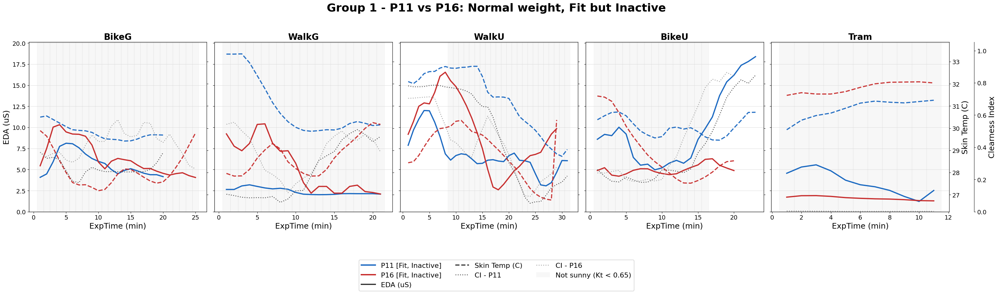

P11 [Fit, Inactive] (183 cm, 72 kg) vs P16 [Fit, Inactive] (174 cm, 63 kg)
Anthropometrics: P11 taller; P11 heavier.
EDA: higher for P11 in BikeU, Tram; P16 in BikeG, WalkG, WalkU.
Skin Temp: higher for P11 in BikeG, WalkG, WalkU, BikeU; P16 in Tram.
Sunny threshold used for Clearness Index: Kt >= 0.65. Very light grey shading marks mean Kt < 0.65.



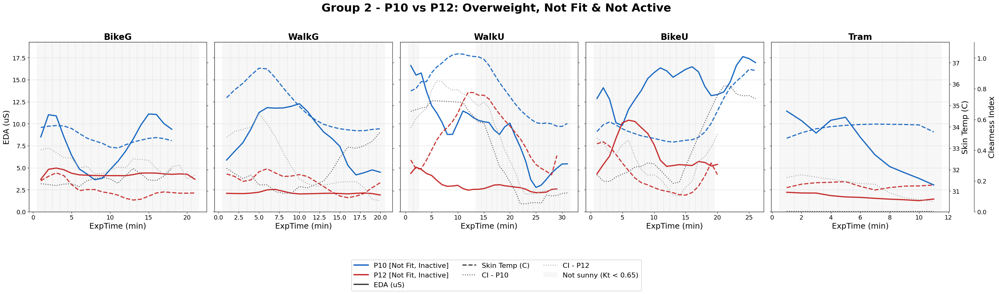

P10 [Not Fit, Inactive] (183 cm, 84 kg) vs P12 [Not Fit, Inactive] (183 cm, 92 kg)
Anthropometrics: similar height; P12 heavier.
EDA: higher for P10 in all phases.
Skin Temp: higher for P10 in all phases.
Sunny threshold used for Clearness Index: Kt >= 0.65. Very light grey shading marks mean Kt < 0.65.



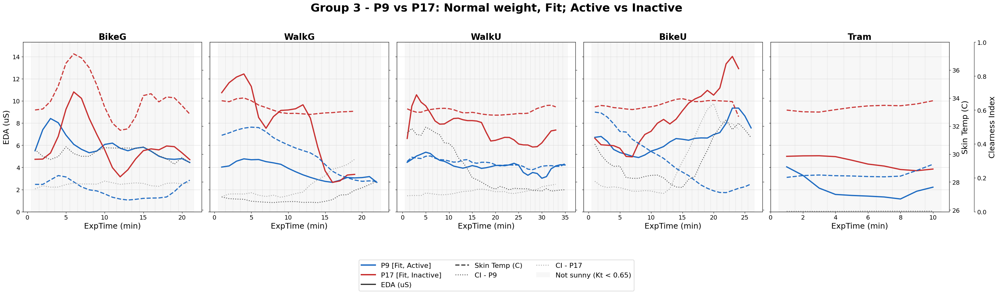

P9 [Fit, Active] (165 cm, 66 kg) vs P17 [Fit, Inactive] (177 cm, 69 kg)
Anthropometrics: P17 taller; P17 heavier.
EDA: higher for P17 in all phases.
Skin Temp: higher for P17 in all phases.
Sunny threshold used for Clearness Index: Kt >= 0.65. Very light grey shading marks mean Kt < 0.65.



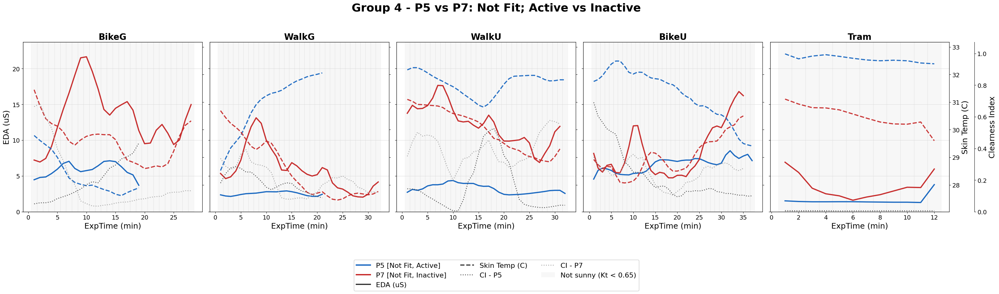

P5 [Not Fit, Active] (191 cm, 62 kg) vs P7 [Not Fit, Inactive] (183 cm, 100 kg)
Anthropometrics: P5 taller; P7 heavier.
EDA: higher for P7 in all phases.
Skin Temp: higher for P5 in WalkG, WalkU, BikeU, Tram; P7 in BikeG.
Sunny threshold used for Clearness Index: Kt >= 0.65. Very light grey shading marks mean Kt < 0.65.



In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

EDA_COL = 'empatica__eda_scl_usiemens'
ST_COL = 'empatica__temperature_celsius'
GHI_COL = 'ucm__sun_gh'
SUN_ALT_COL = 'ucm__sun_alt'
DATE_COL = 'Date'
TIME_COL = 'Time'
CI_COL = 'Clearness_Index'
SUNNY_KT = 0.65
PHASES_CMP = ['BikeG', 'WalkG', 'WalkU', 'BikeU', 'Tram']

TITLE_SIZE = 26
SUBTITLE_SIZE = 20
LABEL_SIZE = 18
TICK_SIZE = 14
LEGEND_SIZE = 16

CI_SMOOTH_WIN = 7  # rolling-mean window (minutes) for Clearness Index

GROUPS_COMP = [
    {
        'title': 'Group 1 - P11 vs P16: Normal weight, Fit but Inactive',
        'pids': [11, 16],
        'colors': {11: '#1565C0', 16: '#C62828'},
    },
    {
        'title': 'Group 2 - P10 vs P12: Overweight, Not Fit & Not Active',
        'pids': [10, 12],
        'colors': {10: '#1565C0', 12: '#C62828'},
    },
    {
        'title': 'Group 3 - P9 vs P17: Normal weight, Fit; Active vs Inactive',
        'pids': [9, 17],
        'colors': {9: '#1565C0', 17: '#C62828'},
    },
    {
        'title': 'Group 4 - P5 vs P7: Not Fit; Active vs Inactive',
        'pids': [5, 7],
        'colors': {5: '#1565C0', 7: '#C62828'},
    },
]

# Two grey shades so the two CI lines are visually distinct
CI_COLORS = ['#555555', '#AAAAAA']


def _first_valid(series):
    vals = pd.to_numeric(series, errors='coerce').dropna()
    if len(vals) == 0:
        return np.nan
    return float(vals.iloc[0])


def _participant_body(pid):
    row = exp_all.loc[exp_all['ParticipantID'] == pid]
    height = _first_valid(row['Height(cm)'])
    weight = _first_valid(row['Weight(kg)'])
    if np.isnan(height):
        height = _first_valid(row['Height'])
    if np.isnan(weight):
        weight = _first_valid(row['Weight'])
    htxt = f"{int(round(height))} cm" if np.isfinite(height) else 'NA cm'
    wtxt = f"{int(round(weight))} kg" if np.isfinite(weight) else 'NA kg'
    return htxt, wtxt, height, weight


def _participant_label(pid):
    row = exp_all.loc[exp_all['ParticipantID'] == pid, ['Fitness', 'Activeness']].iloc[0]
    return f"P{pid} [{row['Fitness']}, {row['Activeness']}]"


def _compute_clearness_index(df):
    dt = pd.to_datetime(
        df[DATE_COL].astype(str) + ' ' + df[TIME_COL].astype(str),
        format='%d-%m-%y %H:%M',
        errors='coerce',
    )
    doy = dt.dt.dayofyear.astype(float).to_numpy()
    ecc = 1.0 + 0.033 * np.cos(2.0 * np.pi * doy / 365.0)
    ecc = np.where(np.isfinite(ecc), ecc, 1.0)
    sun_alt = pd.to_numeric(df[SUN_ALT_COL], errors='coerce').to_numpy(dtype=float)
    ghi = pd.to_numeric(df[GHI_COL], errors='coerce').to_numpy(dtype=float)
    i0h = 1361.0 * ecc * np.maximum(np.sin(np.deg2rad(sun_alt)), 0.0)
    ci = np.where(i0h > 20.0, ghi / i0h, np.nan)
    return np.clip(ci, 0.0, 1.5)


def _axis_limits(df, col, pad_frac=0.08, min_pad=0.05, floor=None):
    vals = pd.to_numeric(df[col], errors='coerce').to_numpy(dtype=float)
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        low, high = 0.0, 1.0
    else:
        low = float(vals.min())
        high = float(vals.max())
        if np.isclose(low, high):
            pad = max(abs(low) * pad_frac, min_pad)
            low -= pad
            high += pad
        else:
            pad = (high - low) * pad_frac
            low -= pad
            high += pad
    if floor is not None:
        low = max(low, floor)
    return (low, high)


def _phase_winner_text(df, col, pid_a, pid_b, label):
    phase_means = (
        df.groupby(['PhaseID', 'ParticipantID'])[col]
        .mean()
        .unstack('ParticipantID')
        .reindex(PHASES_CMP)
    )
    higher_a, higher_b = [], []
    for phase in PHASES_CMP:
        if phase not in phase_means.index:
            continue
        va = phase_means.loc[phase, pid_a] if pid_a in phase_means.columns else np.nan
        vb = phase_means.loc[phase, pid_b] if pid_b in phase_means.columns else np.nan
        if not (np.isfinite(va) and np.isfinite(vb)):
            continue
        if va > vb:
            higher_a.append(phase)
        elif vb > va:
            higher_b.append(phase)
    if len(higher_a) == len(PHASES_CMP):
        return f"{label}: higher for P{pid_a} in all phases."
    if len(higher_b) == len(PHASES_CMP):
        return f"{label}: higher for P{pid_b} in all phases."
    parts = []
    if higher_a:
        parts.append(f"P{pid_a} in {', '.join(higher_a)}")
    if higher_b:
        parts.append(f"P{pid_b} in {', '.join(higher_b)}")
    if not parts:
        return f"{label}: very similar across phases."
    return f"{label}: higher for " + '; '.join(parts) + '.'


def _anthro_note(pid_a, pid_b):
    _, _, ha, wa = _participant_body(pid_a)
    _, _, hb, wb = _participant_body(pid_b)
    notes = []
    if np.isfinite(ha) and np.isfinite(hb):
        if abs(ha - hb) <= 2:
            notes.append('similar height')
        elif ha > hb:
            notes.append(f'P{pid_a} taller')
        else:
            notes.append(f'P{pid_b} taller')
    if np.isfinite(wa) and np.isfinite(wb):
        if abs(wa - wb) <= 2:
            notes.append('similar weight')
        elif wa > wb:
            notes.append(f'P{pid_a} heavier')
        else:
            notes.append(f'P{pid_b} heavier')
    if not notes:
        return ''
    return 'Anthropometrics: ' + '; '.join(notes) + '.'


for grp in GROUPS_COMP:
    pids = grp['pids']
    pid_a, pid_b = pids
    colors = grp['colors']
    grp_df = exp_all[
        exp_all['ParticipantID'].isin(pids) & exp_all['PhaseID'].isin(PHASES_CMP)
    ].copy()
    grp_df[CI_COL] = _compute_clearness_index(grp_df)

    eda_ylim = _axis_limits(grp_df, EDA_COL, pad_frac=0.10, min_pad=0.1, floor=0.0)
    st_ylim  = _axis_limits(grp_df, ST_COL,  pad_frac=0.08, min_pad=0.2)
    ci_ylim  = _axis_limits(grp_df, CI_COL,  pad_frac=0.10, min_pad=0.05, floor=0.0)
    ci_ylim  = (0.0, max(ci_ylim[1], 1.0))

    fig, axes = plt.subplots(1, 5, figsize=(32, 8))
    fig.suptitle(grp['title'], fontsize=TITLE_SIZE, fontweight='bold', y=1.04)

    for ax_idx, phase in enumerate(PHASES_CMP):
        ax    = axes[ax_idx]
        ax_r  = ax.twinx()
        ax_ci = ax.twinx()
        ax_ci.spines['right'].set_position(('axes', 1.14))

        phase_df = grp_df[grp_df['PhaseID'] == phase].copy()

        # Shading: use the average CI across both participants, smoothed
        shade_df = (
            phase_df.groupby('ExpTime')[CI_COL]
            .mean()
            .reset_index()
            .sort_values('ExpTime')
        )
        shade_df['CI_smooth'] = (
            shade_df[CI_COL]
            .rolling(window=CI_SMOOTH_WIN, center=True, min_periods=1)
            .mean()
        )
        for _, shade_row in shade_df.iterrows():
            xt_s   = pd.to_numeric(shade_row['ExpTime'], errors='coerce')
            ci_val = pd.to_numeric(shade_row['CI_smooth'], errors='coerce')
            if np.isfinite(xt_s) and np.isfinite(ci_val) and ci_val < SUNNY_KT:
                ax.axvspan(xt_s - 0.5, xt_s + 0.5, color='#9E9E9E', alpha=0.08, zorder=0)

        ax.set_title(phase, fontsize=SUBTITLE_SIZE, fontweight='bold')
        ax.set_xlabel('ExpTime (min)', fontsize=LABEL_SIZE)
        ax.set_ylim(eda_ylim)
        ax_r.set_ylim(st_ylim)
        ax_ci.set_ylim(ci_ylim)
        ax.grid(True, axis='y', color='#D9D9D9', lw=0.8, alpha=0.9)

        if ax_idx == 0:
            ax.set_ylabel('EDA (uS)', fontsize=LABEL_SIZE)
        else:
            ax.tick_params(axis='y', labelleft=False)

        if ax_idx == len(PHASES_CMP) - 1:
            ax_r.set_ylabel('Skin Temp (C)', fontsize=LABEL_SIZE)
            ax_ci.set_ylabel('Clearness Index', fontsize=LABEL_SIZE)
        else:
            ax_r.tick_params(axis='y', labelright=False)
            ax_ci.tick_params(axis='y', labelright=False, right=False)
            ax_ci.spines['right'].set_visible(False)

        for p_idx, pid in enumerate(pids):
            sub = phase_df[phase_df['ParticipantID'] == pid].sort_values('ExpTime')
            if sub.empty:
                continue

            xt       = pd.to_numeric(sub['ExpTime'],  errors='coerce').to_numpy(dtype=float)
            eda_vals = pd.to_numeric(sub[EDA_COL],    errors='coerce').to_numpy(dtype=float)
            st_vals  = pd.to_numeric(sub[ST_COL],     errors='coerce').to_numpy(dtype=float)
            ci_raw   = pd.to_numeric(sub[CI_COL],     errors='coerce').to_numpy(dtype=float)
            color    = colors[pid]
            ci_color = CI_COLORS[p_idx]  # dark grey for first pid, light grey for second

            ci_smooth = (
                pd.Series(ci_raw)
                .rolling(window=CI_SMOOTH_WIN, center=True, min_periods=1)
                .mean()
                .to_numpy()
            )

            mask_eda = np.isfinite(xt) & np.isfinite(eda_vals)
            mask_st  = np.isfinite(xt) & np.isfinite(st_vals)
            mask_ci  = np.isfinite(xt) & np.isfinite(ci_smooth)

            if mask_eda.any():
                ax.plot(xt[mask_eda], eda_vals[mask_eda], color=color, lw=2.8, ls='-',  alpha=0.97)
            if mask_st.any():
                ax_r.plot(xt[mask_st], st_vals[mask_st], color=color, lw=2.6, ls='--', alpha=0.92)
            if mask_ci.any():
                ax_ci.plot(xt[mask_ci], ci_smooth[mask_ci], color=ci_color, lw=2.0, ls=':', alpha=0.95)

        ax.tick_params(axis='both', labelsize=TICK_SIZE)
        ax_r.tick_params(axis='y',  labelsize=TICK_SIZE)
        ax_ci.tick_params(axis='y', labelsize=TICK_SIZE)
        for spine in ax.spines.values():
            spine.set_linewidth(0.8)
        for spine in ax_r.spines.values():
            spine.set_linewidth(0.8)
        for spine in ax_ci.spines.values():
            spine.set_linewidth(0.8)

    participant_handles = [
        mlines.Line2D([], [], color=colors[pid], lw=3.0, label=_participant_label(pid))
        for pid in pids
    ]
    metric_handles = [
        mlines.Line2D([], [], color='#333333', lw=2.8, ls='-',  label='EDA (uS)'),
        mlines.Line2D([], [], color='#333333', lw=2.6, ls='--', label='Skin Temp (C)'),
        mlines.Line2D([], [], color=CI_COLORS[0], lw=2.0, ls=':', label=f'CI - P{pid_a}'),
        mlines.Line2D([], [], color=CI_COLORS[1], lw=2.0, ls=':', label=f'CI - P{pid_b}'),
        mpatches.Patch(facecolor='#9E9E9E', alpha=0.08, edgecolor='none',
                       label=f'Not sunny (Kt < {SUNNY_KT:.2f})'),
    ]

    fig.legend(
        handles=participant_handles + metric_handles,
        loc='lower center',
        ncol=3,
        bbox_to_anchor=(0.5, -0.13),
        fontsize=LEGEND_SIZE,
        frameon=True,
        edgecolor='#BBBBBB',
    )

    plt.tight_layout(rect=[0, 0.11, 1, 1])
    plt.show()

    h1_txt, w1_txt, _, _ = _participant_body(pid_a)
    h2_txt, w2_txt, _, _ = _participant_body(pid_b)
    print(f"{_participant_label(pid_a)} ({h1_txt}, {w1_txt}) vs {_participant_label(pid_b)} ({h2_txt}, {w2_txt})")
    anthro_note = _anthro_note(pid_a, pid_b)
    if anthro_note:
        print(anthro_note)
    print(_phase_winner_text(grp_df, EDA_COL, pid_a, pid_b, 'EDA'))
    print(_phase_winner_text(grp_df, ST_COL,  pid_a, pid_b, 'Skin Temp'))
    print(f"Sunny threshold used for Clearness Index: Kt >= {SUNNY_KT:.2f}. Very light grey shading marks mean Kt < {SUNNY_KT:.2f}.")
    print('')